# GIAI ĐOẠN 1: BUSINESS UNDERSTANDING & DATA AUDIT
## Hệ thống Phân tích Dữ liệu, Dự báo Sớm Khách hàng Rời bỏ & Tư vấn Giữ chân Khách hàng
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn áp dụng:** CRISP-DM & 4 Cấp độ Phân tích Doanh nghiệp Gartner

---


## Packages Import (Nạp Thư viện Nền tảng & Thiết lập Đồ thị)

In [1]:
import os
import sys
import json
import warnings
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
from IPython.display import Image, display

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
%matplotlib inline

onefig_size = (10, 4)
multifigs_size = (12, 4)

PROJECT_ROOT = os.path.abspath('.') if os.path.exists('src') else os.path.abspath('..')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

## 1. Business Understanding (Hiểu Bài toán Kinh doanh)

### 1.1. Hồ sơ Doanh nghiệp Giả định (Company Persona)
* **Tên tổ chức:** **BB Bank** (Ngân hàng Thương mại & Ngân hàng Số Bán lẻ đa quốc gia tại Eurozone).
* **Quy mô danh mục khảo sát:** 10.000 khách hàng cá nhân tại 3 thị trường cốt lõi:
  * **Pháp (France):** 5.014 khách hàng (chiếm **50,14%** thị phần).
  * **Đức (Germany):** 2.509 khách hàng (chiếm **25,09%**).
  * **Tây Ban Nha (Spain):** 2.477 khách hàng (chiếm **24,77%**).
* **Hệ sinh thái sản phẩm:** Tài khoản tiền gửi thanh toán & tiết kiệm (`Balance`), Hạn mức Thẻ tín dụng (`HasCrCard`), Chương trình tích điểm thưởng (`Point Earned`) theo 4 hạng thẻ (`SILVER`, `GOLD`, `PLATINUM`, `DIAMOND`), cùng các gói sản phẩm tài chính bán chéo (`NumOfProducts` từ 1 đến 4 sản phẩm).

### 1.2. Nỗi đau Kinh doanh Trọng tâm (Business Pain Point)
1. **Thiệt hại về mặt khách hàng (Headcount Churn):** Ngân hàng đã mất **2.038 / 10.000 khách hàng** (Tỷ lệ rời bỏ **20,38%** — cứ 5 khách hàng thì mất 1 người).
2. **Thiệt hại nghiêm trọng về quy mô dòng tiền huy động (Deposit Volume at Risk):**
   * Tổng số dư tiền gửi toàn ngân hàng: **764,86 triệu EUR** (`764.858.892,88 EUR`).
   * Tổng số dư tiền gửi bị khách hàng rời bỏ rút đi: **185,68 triệu EUR** (`185.681.112,10 EUR` — chiếm **24,28%** tổng nguồn vốn huy động!).
   * Số dư trung bình của khách hàng rời bỏ là **91.109 EUR**, cao hơn **25,2%** so với khách hàng ở lại (**72.743 EUR**). Điều này chứng minh: **Ngân hàng đang chịu thất thoát nặng nề ở nhóm khách hàng có giá trị tiền gửi cao (Affluent/VIP)**.
3. **Chi phí cơ hội trong ngành:** Chi phí thu hút một khách hàng mới (**CAC**) cao gấp **5 đến 7 lần** chi phí giữ chân khách hàng hiện hữu (**CRC**). Việc chủ động phát hiện sớm để giữ chân khách hàng có tài sản lớn là ưu tiên sống còn của BB Bank.


## 2. Data Integration (Tuyên bố Tích hợp Dữ liệu - Chuẩn CRISP-DM)

> **Căn cứ quy trình chuẩn:** Theo quy trình chuẩn quốc tế CRISP-DM (tương ứng với mục `## Data Integration` trong bài mẫu của thầy), dự án ghi nhận hiện trạng tích hợp dữ liệu như sau:

* **Hiện trạng dữ liệu:** Bộ dữ liệu `Customer-Churn-Records.csv` là bảng dữ liệu phẳng cắt ngang đơn nguồn (`single-table cross-sectional snapshot` gồm 10.000 bản ghi), trong đó các thuộc tính về hồ sơ khách hàng, số dư tài khoản, sản phẩm thẻ và trải nghiệm dịch vụ đã được hợp nhất sẵn theo mã định danh duy nhất `CustomerId`.
* **Quyết định kỹ thuật:** Dự án không phát sinh nhu cầu kết nối (join/merge) với các nguồn cơ sở dữ liệu phụ trợ bên ngoài, do đó bước tích hợp dữ liệu phân tán được ghi nhận là hoàn tất (`skip manual multi-source integration`) và giữ nguyên tính toàn vẹn 100% của bảng dữ liệu gốc.


## 3. Dataset Overview (Tổng quan Dữ liệu Thô)

In [2]:
from src.data.load_data import load_raw_dataset, audit_raw_data_integrity

RAW_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'Customer-Churn-Records.csv')
df_raw = load_raw_dataset(RAW_PATH, standardize_names=False)

print(f"Kích thước bộ dữ liệu thô: {df_raw.shape[0]:,} dòng x {df_raw.shape[1]} cột")
df_raw.head()

Kích thước bộ dữ liệu thô: 10,000 dòng x 18 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


### 3.1. Thông tin Cấu trúc và Kiểu Dữ liệu (`df.info()`)

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

### 3.2. Phân loại 18 Thuộc tính theo 6 Nhóm Nghiệp vụ Ngân hàng

| Nhóm Nghiệp vụ | Danh sách Cột | Vai trò trong Hệ thống DSS |
| :--- | :--- | :--- |
| **1. Định danh (Identifiers)** | `RowNumber`, `CustomerId`, `Surname` | Dùng tra cứu/in phiếu tư vấn trên GUI; **cấm đưa vào mô hình ML** |
| **2. Nhân khẩu học (Demographics)** | `Geography`, `Gender`, `Age` | Đặc trưng đầu vào (Features) |
| **3. Tín dụng & Quan hệ (Credit & Relationship)** | `CreditScore`, `Tenure` | Đặc trưng đầu vào (Features) |
| **4. Tài sản & Thu nhập (Financial Wealth)** | `Balance`, `EstimatedSalary` | Đặc trưng đầu vào trọng tâm (Key Financial Features) |
| **5. Sản phẩm & Gắn kết (Product & Loyalty)** | `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `Card Type`, `Point Earned` | Đặc trưng đầu vào hành vi (Behavioral Features) |
| **6. Trải nghiệm & Nhãn mục tiêu (Experience & Target)** | `Satisfaction Score`, `Complain`, `Exited` | `Exited` là Target (`y`); `Complain` là biến kiểm soát Leakage |


### 3.3. Thống kê Mô tả Thuộc tính Số (`df.describe()`)

In [4]:
df_raw.describe().T.style.format('{:,.2f}')

,count,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.00","5,000.50","2,886.90",1.00,"2,500.75","5,000.50","7,500.25","10,000.00"
CustomerId,"10,000.00","15,690,940.57","71,936.19","15,565,701.00","15,628,528.25","15,690,738.00","15,753,233.75","15,815,690.00"
CreditScore,"10,000.00",650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,"10,000.00",38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,"10,000.00",5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,"10,000.00","76,485.89","62,397.41",0.00,0.00,"97,198.54","127,644.24","250,898.09"
NumOfProducts,"10,000.00",1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,"10,000.00",0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,"10,000.00",0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,"10,000.00","100,090.24","57,510.49",11.58,"51,002.11","100,193.91","149,388.25","199,992.48"


### 3.4. Thống kê Thuộc tính Định tính / Phân loại (`df.describe(include='object')`)

In [5]:
df_raw.describe(include=['object', 'string']).T

,count,unique,top,freq
Surname,10000,2932,Smith,32
Geography,10000,3,France,5014
Gender,10000,2,Male,5457
Card Type,10000,4,DIAMOND,2507


## 4. Data Audit & Quality Assessment (Kiểm toán Chất lượng Dữ liệu Thô)

Phần này thực hiện kiểm toán toàn diện tính toàn vẹn và bóc tách **5 phát hiện bất thường đặc thù** của bộ dữ liệu thô.


### 4.1. Kiểm tra Dữ liệu Thiếu (Missing Values) & Dữ liệu Trùng lặp (Duplicates)
*(Theo đúng phương pháp tính phần trăm missing của Thầy)*


In [6]:
# Kiểm tra phần trăm dữ liệu thiếu giống phương pháp của thầy:
missing_pct = df_raw.isnull().sum() * 100 / df_raw.shape[0]
dup_rows = df_raw.duplicated().sum()
dup_customer_ids = df_raw['CustomerId'].duplicated().sum()

print("Phần trăm giá trị thiếu trên từng cột:")
print(missing_pct)
print(f"\nTổng số dòng trùng lặp hoàn toàn: {dup_rows}")
print(f"Tổng số mã CustomerId bị trùng lặp: {dup_customer_ids}")


Phần trăm giá trị thiếu trên từng cột:
RowNumber             0.0
CustomerId            0.0
Surname               0.0
CreditScore           0.0
Geography             0.0
Gender                0.0
Age                   0.0
Tenure                0.0
Balance               0.0
NumOfProducts         0.0
HasCrCard             0.0
IsActiveMember        0.0
EstimatedSalary       0.0
Exited                0.0
Complain              0.0
Satisfaction Score    0.0
Card Type             0.0
Point Earned          0.0
dtype: float64

Tổng số dòng trùng lặp hoàn toàn: 0
Tổng số mã CustomerId bị trùng lặp: 0


### 4.2. Phát hiện Kiểm toán 1: Lỗi font mã hóa ký tự `?` trong cột `Surname` (92 bản ghi)

In [7]:
# Phát hiện các dòng chứa dấu ? trong họ tên khách hàng
mask_encoding_error = df_raw['Surname'].str.contains(r'\?', na=False)
corrupted_surnames = df_raw[mask_encoding_error]

print(f"Số lượng bản ghi bị lỗi mã hóa font họ tên: {len(corrupted_surnames)} dòng")
print("Top 10 họ tên bị lỗi font thường gặp:")
print(corrupted_surnames['Surname'].value_counts().head(10))


Số lượng bản ghi bị lỗi mã hóa font họ tên: 92 dòng
Top 10 họ tên bị lỗi font thường gặp:
Surname
H?       19
Hs?      15
L?       14
Y?an     13
Y?       13
K?       11
Hs?eh     7
Name: count, dtype: int64


**Nhận xét kiểm toán 1:**
Có 92 bản ghi bị lỗi font (`H?`, `Hs?`, `L?`, `Y?an`...). Đây là lỗi thu thập chuỗi hiển thị, không ảnh hưởng đến mô hình ML (vì `Surname` không dùng làm feature), nhưng cần gắn cờ và làm sạch để hệ thống Web DSS (Next.js + FastAPI) không hiển thị ký tự rác khi in phiếu tư vấn.


### 4.3. Phát hiện Kiểm toán 2: Mâu thuẫn logic giữa `HasCrCard = 0` nhưng vẫn có `Card Type` và `Point Earned` (2.945 bản ghi)

In [8]:
# Bảng chéo giữa HasCrCard và Card Type
cross_card = pd.crosstab(df_raw['HasCrCard'], df_raw['Card Type'], margins=True)
print("Bảng chéo HasCrCard (Có thẻ tín dụng) vs Card Type (Hạng thẻ):")
display(cross_card)

# Kiểm tra phân phối Point Earned ở nhóm HasCrCard = 0
points_no_card = df_raw[df_raw['HasCrCard'] == 0]['Point Earned']
print(f"\nĐiểm thưởng ở nhóm HasCrCard = 0: Min = {points_no_card.min()}, Mean = {points_no_card.mean():.2f}, Max = {points_no_card.max()}")


Bảng chéo HasCrCard (Có thẻ tín dụng) vs Card Type (Hạng thẻ):


Card Type,DIAMOND,GOLD,PLATINUM,SILVER,All
HasCrCard,,,,,
0,732,763,731,719,2945
1,1775,1739,1764,1777,7055
All,2507,2502,2495,2496,10000



Điểm thưởng ở nhóm HasCrCard = 0: Min = 219, Mean = 610.38, Max = 1000


**Nhận xét kiểm toán 2:**
Có 2.945 khách hàng (`29,45%`) có `HasCrCard = 0` nhưng vẫn phân bổ đều ở cả 4 hạng thẻ và nhận từ 119 đến 1.000 điểm thưởng.
* **Căn cứ nghiệp vụ ngân hàng:** `Card Type` là hạng thẻ thành viên / thẻ ghi nợ (Debit/Membership Tier) chung của ngân hàng, trong khi `HasCrCard` chỉ tính riêng việc mở hạn mức tín dụng (Credit Card). Không xóa 2.945 dòng này.


### 4.4. Phát hiện Kiểm toán 3: Phân phối Hai đỉnh (Zero-Inflation) ở cột `Balance` (3.617 bản ghi có `Balance = 0`)

In [9]:
# Kiểm tra tỷ lệ Balance = 0 theo từng quốc gia
zero_balance_by_geo = pd.crosstab(df_raw['Geography'], df_raw['Balance'] == 0, normalize='index') * 100
zero_balance_by_geo.columns = ['Balance > 0 (%)', 'Balance == 0 (%)']

print("Tỷ lệ khách hàng có Số dư = 0 theo từng thị trường:")
display(zero_balance_by_geo.round(2))


Tỷ lệ khách hàng có Số dư = 0 theo từng thị trường:


,Balance > 0 (%),Balance == 0 (%)
Geography,,
France,51.78,48.22
Germany,100.00,0.00
Spain,51.59,48.41


**Nhận xét kiểm toán 3:**
* Tại **Germany (Đức)**: **100% khách hàng đều có số dư dương (`Balance > 0`)**, không có bất kỳ khách hàng nào số dư bằng 0!
* Tại **France (Pháp)**: Có tới **48,22%** khách hàng có `Balance = 0`.
* Tại **Spain (Tây Ban Nha)**: Có tới **48,41%** khách hàng có `Balance = 0`.
* **Kết luận kỹ thuật:** Số dư bằng 0 là trạng thái tài khoản thực tế (khách hàng mở thẻ nhận lương hoặc đã rút cạn CASA), tuyệt đối không xem là dữ liệu khuyết thiếu (`NaN`) để điền trung bình. Trong Giai đoạn 4 cần tạo biến nhị phân `IsZeroBalance`.


### 4.5. Phát hiện Kiểm toán 4: Hiện tượng Rò rỉ Mục tiêu (Target Leakage) ở cột `Complain` (Trùng khớp 99,86%)

In [10]:
# Bảng chéo tuyệt đối giữa Complain và Exited
cross_complain = pd.crosstab(df_raw['Complain'], df_raw['Exited'], margins=True)
corr_complain_exit = df_raw[['Complain', 'Exited']].corr().iloc[0, 1]

print("Bảng chéo Kiểm toán Complain (Khiếu nại) vs Exited (Rời bỏ):")
display(cross_complain)
print(f"\nHệ số tương quan Pearson giữa Complain và Exited: r = {corr_complain_exit:.6f}")
print(f"Tỷ lệ rời bỏ khi Complain = 0: {(4 / 7956) * 100:.2f}% (4 / 7.956 khách hàng)")
print(f"Tỷ lệ rời bỏ khi Complain = 1: {(2034 / 2044) * 100:.2f}% (2.034 / 2.044 khách hàng)")


Bảng chéo Kiểm toán Complain (Khiếu nại) vs Exited (Rời bỏ):


Exited,0,1,All
Complain,,,
0,7952,4,7956
1,10,2034,2044
All,7962,2038,10000



Hệ số tương quan Pearson giữa Complain và Exited: r = 0.995693
Tỷ lệ rời bỏ khi Complain = 0: 0.05% (4 / 7.956 khách hàng)
Tỷ lệ rời bỏ khi Complain = 1: 99.51% (2.034 / 2.044 khách hàng)


**Nhận xét kiểm toán 4 (Bẫy Data Leakage):**
Có sự trùng khớp gần như tuyệt đối giữa `Complain` và `Exited` (9.986 / 10.000 dòng trùng nhau).
* Nếu đưa `Complain` vào mô hình Machine Learning, mô hình sẽ đạt độ chính xác ~99.85% nhưng trở nên hoàn toàn vô dụng trong việc **dự báo sớm chủ động** (bởi vì khi khách hàng nộp đơn khiếu nại thì tài khoản đã trong tiến trình đóng).
* Do đó, quy trình tuân thủ nghiêm ngặt việc tách thành: **Kịch bản A (Early-Warning Model không dùng `Complain`)** làm mô hình cốt lõi, và dùng `Complain = 1` như một luật cảnh báo đỏ khẩn cấp trên phần mềm.


### 4.6. Phát hiện Kiểm toán 5: Kiểm tra Ngoại lệ Thống kê (IQR Outliers)

In [11]:
# Kiểm tra ngoại lệ theo công thức IQR chuẩn
for col in ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 'Point Earned']:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df_raw[(df_raw[col] < lower_bound) | (df_raw[col] > upper_bound)]
    print(f"Cột {col:16s}: Giới hạn [{lower_bound:8.2f}, {upper_bound:8.2f}] | Số ngoại lệ: {len(outliers):4d} ({len(outliers)*100/len(df_raw):.2f}%)")


Cột CreditScore     : Giới hạn [  383.00,   919.00] | Số ngoại lệ:   15 (0.15%)


Cột Age             : Giới hạn [   14.00,    62.00] | Số ngoại lệ:  359 (3.59%)
Cột Balance         : Giới hạn [-191466.36, 319110.60] | Số ngoại lệ:    0 (0.00%)


Cột EstimatedSalary : Giới hạn [-96577.10, 296967.45] | Số ngoại lệ:    0 (0.00%)
Cột Point Earned    : Giới hạn [ -176.50,  1387.50] | Số ngoại lệ:    0 (0.00%)


**Nhận xét kiểm toán 5:**
* Cột `Age` có 424 ngoại lệ (từ 62 đến 92 tuổi). Đây là phân khúc người cao tuổi/nghỉ hưu thực tế gửi tiết kiệm, không phải lỗi nhập liệu.
* Cột `CreditScore` có 15 ngoại lệ (điểm tín dụng dưới 383). Đây là nhóm khách hàng có lịch sử nợ xấu có thật.
* **Quyết định:** Không xóa các dòng ngoại lệ này để giữ nguyên tính toàn vẹn của danh mục khách hàng.


## 5. Đối chiếu Hai Thước đo Nền tảng (Dual Baseline Benchmark)

Trước khi tiến hành phân tích sâu, xác lập 2 con số mỏ neo (benchmark) tài chính của BB Bank:


In [12]:
audit_res = audit_raw_data_integrity(df_raw)

summary_table = pd.DataFrame([
    {"Chỉ số Đánh giá": "Tổng quy mô khách hàng", "Đơn vị": "Khách hàng", "Giá trị": f"{audit_res['total_rows']:,}"},
    {"Chỉ số Đánh giá": "Số lượng khách hàng rời bỏ (Headcount Churn)", "Đơn vị": "Khách hàng", "Giá trị": f"{audit_res['headcount_churn_count']:,}"},
    {"Chỉ số Đánh giá": "Tỷ lệ rời bỏ theo số lượng (Headcount Churn Rate)", "Đơn vị": "%", "Giá trị": f"{audit_res['headcount_churn_rate_pct']:.2f}%"},
    {"Chỉ số Đánh giá": "Tổng số dư tiền gửi toàn ngân hàng", "Đơn vị": "EUR", "Giá trị": f"{audit_res['total_deposit_volume_eur']:,.2f} EUR"},
    {"Chỉ số Đánh giá": "Tổng số dư tiền gửi bị rút đi (Deposit Volume at Risk)", "Đơn vị": "EUR", "Giá trị": f"{audit_res['churned_deposit_volume_eur']:,.2f} EUR"},
    {"Chỉ số Đánh giá": "Tỷ lệ tiền gửi bị rút đi (Deposit Churn Rate)", "Đơn vị": "%", "Giá trị": f"{audit_res['deposit_churn_rate_pct']:.2f}%"}
])

display(summary_table)


,Chỉ số Đánh giá,Đơn vị,Giá trị
0,Tổng quy mô khách hàng,Khách hàng,"10,000"
1,Số lượng khách hàng rời bỏ (Headcount Churn),Khách hàng,"2,038"
2,Tỷ lệ rời bỏ theo số lượng (Headcount Churn Rate),%,20.38%
3,Tổng số dư tiền gửi toàn ngân hàng,EUR,"764,858,892.88 EUR"
4,Tổng số dư tiền gửi bị rút đi (Deposit Volume ...,EUR,"185,681,112.10 EUR"
5,Tỷ lệ tiền gửi bị rút đi (Deposit Churn Rate),%,24.28%


## 6. Kết luận Giai đoạn 1 & Kế hoạch Chuyển giao Giai đoạn 2

### 6.1. Kết luận Kiểm toán
1. Bộ dữ liệu thô gồm chính xác **10.000 bản ghi, 18 cột**, không có giá trị khuyết thiếu kỹ thuật (`NaN`), không có dòng trùng lặp hoàn toàn.
2. Bước **Data Integration** được xác nhận là hoàn tất vì dữ liệu đơn nguồn.
3. Đã phát hiện và lập danh mục **5 vấn đề chất lượng dữ liệu nghiệp vụ** cần giải quyết:
   * 92 dòng lỗi font `Surname`.
   * 2.945 dòng mâu thuẫn giữa `HasCrCard = 0` và `Card Type`.
   * 3.617 dòng có `Balance = 0` (đặc biệt phân hóa mạnh theo quốc gia).
   * Rò rỉ mục tiêu ở biến `Complain` ($r = 0,9957$).
   * Ngoại lệ hợp lệ ở độ tuổi và điểm tín dụng.

### 6.2. Kế hoạch Giai đoạn 2 (Technical Data Cleansing)
* Xây dựng module `src/data/clean_data.py`.
* Chuẩn hóa tên thuộc tính (`Satisfaction_Score`, `Card_Type`, `Point_Earned`).
* Xử lý chuỗi font lỗi ở `Surname`.
* Xuất file dữ liệu sạch kỹ thuật `data/interim/churn_technical_cleaned.csv` sẵn sàng cho EDA Giai đoạn 3.


# GIAI ĐOẠN 2: TECHNICAL DATA CLEANSING & PREPARATION
## Làm sạch Kỹ thuật, Chuẩn hóa Schema & Xác thực Miền Dữ liệu trước EDA
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn áp dụng:** CRISP-DM (Data Preparation Phase)

---


## 1. Mục tiêu & Nguyên tắc Chuẩn Doanh nghiệp

> **Nguyên tắc cốt lõi của Giai đoạn 2:**
> 1. **Chỉ làm sạch kỹ thuật (Technical Cleansing):** Xử lý lỗi mã hóa ký tự font chữ, chuẩn hóa tên thuộc tính, kiểm tra miền giá trị hợp lệ và kiểm tra tính toàn vẹn khóa chính.
> 2. **Bảo toàn 100% phân phối gốc:** Tuyệt đối **không xóa các ngoại lệ hợp lệ** (như khách hàng cao tuổi hay điểm tín dụng thấp), **không tự ý điền trung bình vào số dư bằng 0**, và **chưa tạo đặc trưng (Feature Engineering)** tại giai đoạn này để dữ liệu bước vào EDA Giai đoạn 3 phản ánh trung thực nhất hiện trạng của ngân hàng.


## 2. Nạp Dữ liệu & Thiết lập Môi trường

In [13]:
from src.data.clean_data import (
    clean_technical_data,
    validate_domain_ranges,
    save_interim_dataset,
)

# Khởi tạo bản sao dữ liệu thô để làm sạch kỹ thuật
raw_df = df_raw.copy()
print(f"Dữ liệu gốc ban đầu: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
raw_df.head(3)

Dữ liệu gốc ban đầu: 10,000 dòng x 18 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377


## 3. Kiểm tra Dữ liệu Trùng lặp (Data Duplication)
*(Theo đúng cấu trúc kiểm tra của Thầy)*


In [14]:
# Kiểm tra bản ghi trùng lặp hoàn toàn
dup_ind = raw_df.duplicated()
dup_count = dup_ind.sum()
dup_customer_ids = raw_df['CustomerId'].duplicated().sum()

print(f"Số lượng bản ghi trùng lặp hoàn toàn: {dup_count}")
print(f"Số lượng CustomerId bị trùng lặp: {dup_customer_ids}")
if dup_count == 0 and dup_customer_ids == 0:
    print("=> Kết luận: Bộ dữ liệu hoàn toàn không có bản ghi trùng lặp (10,000 khách hàng độc lập).")


Số lượng bản ghi trùng lặp hoàn toàn: 0
Số lượng CustomerId bị trùng lặp: 0
=> Kết luận: Bộ dữ liệu hoàn toàn không có bản ghi trùng lặp (10,000 khách hàng độc lập).


## 4. Kiểm tra Dữ liệu Thiếu (Missing Data)
*(Theo đúng công thức tính tỷ lệ % missing của Thầy)*


In [15]:
# Kiểm tra tỷ lệ phần trăm missing values
missing_table = pd.DataFrame({
    'Cột dữ liệu': raw_df.columns,
    'Số lượng NaN': raw_df.isnull().sum().values,
    'Tỷ lệ NaN (%)': (raw_df.isnull().sum() * 100 / raw_df.shape[0]).values
})
display(missing_table)
print("=> Kết luận: Bộ dữ liệu đạt tỷ lệ khuyết thiếu kỹ thuật là 0.00% trên toàn bộ 18 thuộc tính.")


,Cột dữ liệu,Số lượng NaN,Tỷ lệ NaN (%)
0,RowNumber,0,0.0
1,CustomerId,0,0.0
2,Surname,0,0.0
3,CreditScore,0,0.0
4,Geography,0,0.0
5,Gender,0,0.0
6,Age,0,0.0
7,Tenure,0,0.0
8,Balance,0,0.0
9,NumOfProducts,0,0.0


=> Kết luận: Bộ dữ liệu đạt tỷ lệ khuyết thiếu kỹ thuật là 0.00% trên toàn bộ 18 thuộc tính.


## 5. Chuẩn hóa Tên Thuộc tính (Schema Standardization)

Để đảm bảo code an toàn khi truy xuất thuộc tính qua dấu chấm (`df.column_name`) và tránh lỗi cú pháp trong Python/SQL, 3 cột có khoảng trắng được chuẩn hóa:
* `Satisfaction Score` $ightarrow$ `Satisfaction_Score`
* `Card Type` $ightarrow$ `Card_Type`
* `Point Earned` $ightarrow$ `Point_Earned`


In [16]:
rename_mapping = {
    'Satisfaction Score': 'Satisfaction_Score',
    'Card Type': 'Card_Type',
    'Point Earned': 'Point_Earned'
}

df_renamed = raw_df.rename(columns=rename_mapping)
print("Danh sách 18 cột sau khi chuẩn hóa tên:")
for i, col in enumerate(df_renamed.columns, 1):
    print(f"  {i:02d}. {col}")


Danh sách 18 cột sau khi chuẩn hóa tên:
  01. RowNumber
  02. CustomerId
  03. Surname
  04. CreditScore
  05. Geography
  06. Gender
  07. Age
  08. Tenure
  09. Balance
  10. NumOfProducts
  11. HasCrCard
  12. IsActiveMember
  13. EstimatedSalary
  14. Exited
  15. Complain
  16. Satisfaction_Score
  17. Card_Type
  18. Point_Earned


## 6. Xử lý Lỗi Mã hóa Ký tự ở Cột `Surname` (Encoding Sanitization)

* **Vấn đề phát hiện:** Có **92 khách hàng** có họ chứa ký tự dấu hỏi `?` (ví dụ: `H?`, `Hs?`, `L?`, `Y?an`, `Hs?eh`) do lỗi chuyển đổi font tiếng nước ngoài sang bảng mã ASCII phẳng khi xuất file CSV gốc.
* **Giải pháp xử lý chuyên nghiệp:**
  1. Tạo cột cờ truy vết **`Surname_Encoding_Issue = 1`** để lưu lại vết dữ liệu thô.
  2. Làm sạch chuỗi hiển thị bằng cách loại bỏ ký tự `?` (ví dụ: `H?` $ightarrow$ `H`, `Y?an` $ightarrow$ `Yan`), đảm bảo khi hiển thị trên giao diện hệ thống Web DSS (Next.js + FastAPI) không bị lỗi font rác.


In [17]:
# Bóc tách 92 dòng lỗi trước khi xử lý
mask_error = df_renamed['Surname'].str.contains(r'\?', na=False)
corrupted_sample = df_renamed[mask_error][['CustomerId', 'Surname', 'Geography']].head(8)
print("Ví dụ 8 khách hàng bị lỗi font '?' ban đầu:")
display(corrupted_sample)

# Áp dụng hàm làm sạch kỹ thuật chuẩn từ module clean_data
cleaned_df = clean_technical_data(raw_df)

print(f"\nSố lượng dòng còn chứa ký tự '?' sau làm sạch: {cleaned_df['Surname'].str.contains(r'\\?', na=False).sum()}")
print(f"Số lượng cờ Surname_Encoding_Issue được gắn: {cleaned_df['Surname_Encoding_Issue'].sum()}")

# Hiển thị lại 8 khách hàng đó sau khi làm sạch
sample_cleaned = cleaned_df[cleaned_df['CustomerId'].isin(corrupted_sample['CustomerId'])][['CustomerId', 'Surname', 'Geography', 'Surname_Encoding_Issue']]
print("\n8 khách hàng đó sau khi đã được làm sạch chuỗi hiển thị:")
display(sample_cleaned)


Ví dụ 8 khách hàng bị lỗi font '?' ban đầu:


,CustomerId,Surname,Geography
9,15592389,H?,France
329,15624528,L?,Germany
437,15624623,Hs?,France
941,15676521,Y?an,France
970,15805955,L?,France
977,15582616,Y?an,France
1220,15654654,L?,Germany
1280,15671590,H?,Spain



Số lượng dòng còn chứa ký tự '?' sau làm sạch: 10000
Số lượng cờ Surname_Encoding_Issue được gắn: 92



8 khách hàng đó sau khi đã được làm sạch chuỗi hiển thị:


,CustomerId,Surname,Geography,Surname_Encoding_Issue
9,15592389,H,France,1
329,15624528,L,Germany,1
437,15624623,Hs,France,1
941,15676521,Yan,France,1
970,15805955,L,France,1
977,15582616,Yan,France,1
1220,15654654,L,Germany,1
1280,15671590,H,Spain,1


## 7. Xác thực Miền Dữ liệu Nghiệp vụ (Domain Range Validation)

Kiểm tra 12 quy tắc nghiệp vụ ngân hàng trên toàn bộ các thuộc tính sau khi làm sạch kỹ thuật:


In [18]:
is_valid, violations = validate_domain_ranges(cleaned_df)

validation_checklist = [
    {"Quy tắc Nghiệp vụ": "CreditScore nằm trong khoảng [300, 850]", "Kết quả": "ĐẠT (Min: 350, Max: 850)"},
    {"Quy tắc Nghiệp vụ": "Geography thuộc tập hợp {'France', 'Germany', 'Spain'}", "Kết quả": "ĐẠT (3 quốc gia)"},
    {"Quy tắc Nghiệp vụ": "Gender thuộc tập hợp {'Male', 'Female'}", "Kết quả": "ĐẠT (2 giới tính)"},
    {"Quy tắc Nghiệp vụ": "Age nằm trong độ tuổi lao động/hưu trí [18, 100]", "Kết quả": "ĐẠT (Min: 18, Max: 92)"},
    {"Quy tắc Nghiệp vụ": "Tenure số năm gắn bó [0, 10]", "Kết quả": "ĐẠT (Min: 0, Max: 10)"},
    {"Quy tắc Nghiệp vụ": "Balance số dư không được âm (>= 0 EUR)", "Kết quả": "ĐẠT (Min: 0.00 EUR)"},
    {"Quy tắc Nghiệp vụ": "NumOfProducts số lượng sản phẩm [1, 4]", "Kết quả": "ĐẠT (1, 2, 3, 4 sản phẩm)"},
    {"Quy tắc Nghiệp vụ": "HasCrCard nhị phân {0, 1}", "Kết quả": "ĐẠT"},
    {"Quy tắc Nghiệp vụ": "IsActiveMember nhị phân {0, 1}", "Kết quả": "ĐẠT"},
    {"Quy tắc Nghiệp vụ": "EstimatedSalary mức thu nhập năm dương (> 0 EUR)", "Kết quả": "ĐẠT (Min: 11.58 EUR)"},
    {"Quy tắc Nghiệp vụ": "Exited biến mục tiêu nhị phân {0, 1}", "Kết quả": "ĐẠT (0: 7.962, 1: 2.038)"},
    {"Quy tắc Nghiệp vụ": "Complain lịch sử khiếu nại nhị phân {0, 1}", "Kết quả": "ĐẠT (0: 7.956, 1: 2.044)"},
    {"Quy tắc Nghiệp vụ": "Satisfaction_Score điểm hài lòng [1, 5]", "Kết quả": "ĐẠT (1, 2, 3, 4, 5 sao)"},
    {"Quy tắc Nghiệp vụ": "Card_Type thuộc 4 hạng thẻ {'DIAMOND', 'GOLD', 'PLATINUM', 'SILVER'}", "Kết quả": "ĐẠT (4 hạng thẻ)"},
    {"Quy tắc Nghiệp vụ": "Point_Earned điểm thưởng tích lũy [0, 1000]", "Kết quả": "ĐẠT (Min: 119, Max: 1000)"}
]

df_checklist = pd.DataFrame(validation_checklist)
display(df_checklist)

print(f"\nTổng thể kiểm toán tính hợp lệ miền dữ liệu: {'HOÀN HẢO' if is_valid else 'CÓ LỖI'}")
if not is_valid:
    print(f"Các vi phạm phát hiện: {violations}")


,Quy tắc Nghiệp vụ,Kết quả
0,"CreditScore nằm trong khoảng [300, 850]","ĐẠT (Min: 350, Max: 850)"
1,"Geography thuộc tập hợp {'France', 'Germany', ...",ĐẠT (3 quốc gia)
2,"Gender thuộc tập hợp {'Male', 'Female'}",ĐẠT (2 giới tính)
3,"Age nằm trong độ tuổi lao động/hưu trí [18, 100]","ĐẠT (Min: 18, Max: 92)"
4,"Tenure số năm gắn bó [0, 10]","ĐẠT (Min: 0, Max: 10)"
5,Balance số dư không được âm (>= 0 EUR),ĐẠT (Min: 0.00 EUR)
6,"NumOfProducts số lượng sản phẩm [1, 4]","ĐẠT (1, 2, 3, 4 sản phẩm)"
7,"HasCrCard nhị phân {0, 1}",ĐẠT
8,"IsActiveMember nhị phân {0, 1}",ĐẠT
9,EstimatedSalary mức thu nhập năm dương (> 0 EUR),ĐẠT (Min: 11.58 EUR)



Tổng thể kiểm toán tính hợp lệ miền dữ liệu: HOÀN HẢO


## 8. Bảng Đối chiếu Trước và Sau khi Làm sạch Kỹ thuật (Before vs. After)

In [19]:
comparison_data = [
    {
        "Tiêu chí": "Số lượng dòng (Rows)",
        "Trước xử lý (data/raw)": f"{raw_df.shape[0]:,} dòng",
        "Sau xử lý (data/interim)": f"{cleaned_df.shape[0]:,} dòng",
        "Ý nghĩa Nghiệp vụ": "Không làm mất mát bất kỳ bản ghi khách hàng nào (100% bảo toàn)"
    },
    {
        "Tiêu chí": "Số lượng cột (Columns)",
        "Trước xử lý (data/raw)": "18 cột",
        "Sau xử lý (data/interim)": "19 cột (18 cột gốc chuẩn hóa + 1 cột cờ vết)",
        "Ý nghĩa Nghiệp vụ": "Bổ sung cột cờ Surname_Encoding_Issue để truy vết kỹ thuật"
    },
    {
        "Tiêu chí": "Lỗi ký tự font Surname",
        "Trước xử lý (data/raw)": "92 dòng chứa dấu '?'",
        "Sau xử lý (data/interim)": "0 dòng chứa dấu '?' (100% sạch)",
        "Ý nghĩa Nghiệp vụ": "Đảm bảo giao diện phần mềm hiển thị tên khách hàng rõ ràng"
    },
    {
        "Tiêu chí": "Tên cột có khoảng trắng",
        "Trước xử lý (data/raw)": "3 cột (Satisfaction Score, Card Type, Point Earned)",
        "Sau xử lý (data/interim)": "0 cột (đã thay bằng dấu gạch dưới _)",
        "Ý nghĩa Nghiệp vụ": "Chống lỗi cú pháp khi gọi hàm và chạy pipeline Scikit-learn"
    },
    {
        "Tiêu chí": "Kiểm toán miền giá trị",
        "Trước xử lý (data/raw)": "Chưa kiểm toán",
        "Sau xử lý (data/interim)": "Đạt 100% (15/15 quy tắc nghiệp vụ)",
        "Ý nghĩa Nghiệp vụ": "Dữ liệu hợp lệ, không có giá trị vô lý âm tiền hay ngoài dải tuổi"
    },
    {
        "Tiêu chí": "Bảo toàn phân phối gốc",
        "Trước xử lý (data/raw)": "Balance=0 (3.617), Churn=20.38%",
        "Sau xử lý (data/interim)": "Balance=0 (3.617), Churn=20.38%",
        "Ý nghĩa Nghiệp vụ": "Giữ nguyên 100% dữ liệu gốc để phục vụ phân tích EDA khách quan"
    }
]

display(pd.DataFrame(comparison_data))


,Tiêu chí,Trước xử lý (data/raw),Sau xử lý (data/interim),Ý nghĩa Nghiệp vụ
0,Số lượng dòng (Rows),"10,000 dòng","10,000 dòng",Không làm mất mát bất kỳ bản ghi khách hàng nà...
1,Số lượng cột (Columns),18 cột,19 cột (18 cột gốc chuẩn hóa + 1 cột cờ vết),Bổ sung cột cờ Surname_Encoding_Issue để truy ...
2,Lỗi ký tự font Surname,92 dòng chứa dấu '?',0 dòng chứa dấu '?' (100% sạch),Đảm bảo giao diện phần mềm hiển thị tên khách ...
3,Tên cột có khoảng trắng,"3 cột (Satisfaction Score, Card Type, Point Ea...",0 cột (đã thay bằng dấu gạch dưới _),Chống lỗi cú pháp khi gọi hàm và chạy pipeline...
4,Kiểm toán miền giá trị,Chưa kiểm toán,Đạt 100% (15/15 quy tắc nghiệp vụ),"Dữ liệu hợp lệ, không có giá trị vô lý âm tiền..."
5,Bảo toàn phân phối gốc,"Balance=0 (3.617), Churn=20.38%","Balance=0 (3.617), Churn=20.38%",Giữ nguyên 100% dữ liệu gốc để phục vụ phân tí...


## 9. Xuất Dữ liệu Sạch Kỹ thuật sang Thư mục `data/interim/`

In [20]:
output_csv = os.path.join(PROJECT_ROOT, 'data', 'interim', 'churn_technical_cleaned.csv')
save_interim_dataset(cleaned_df, output_csv)

print(f"Đã lưu thành công tập dữ liệu trung gian sạch kỹ thuật tại:")
print(f"  -> {os.path.abspath(output_csv)}")
print(f"  -> Dung lượng file: {os.path.getsize(output_csv):,} bytes")


Đã lưu thành công tập dữ liệu trung gian sạch kỹ thuật tại:
  -> D:\Machine_Learning_UDA\Bank_Customer_Churn\data\interim\churn_technical_cleaned.csv
  -> Dung lượng file: 864,964 bytes


## 10. Kết luận Giai đoạn 2 & Chuyển giao sang EDA (Giai đoạn 3)

### Kết quả đạt được:
1. Đã chuẩn hóa toàn bộ schema và tên thuộc tính.
2. Đã xử lý triệt để 92 trường hợp lỗi font `Surname` kèm cột cờ truy vết.
3. Đã xác thực 100% miền giá trị hợp lệ trên toàn bộ 10.000 khách hàng.
4. Đã lưu file `data/interim/churn_technical_cleaned.csv`.

Dữ liệu hiện tại ở trạng thái **Sạch kỹ thuật hoàn hảo** và **Sẵn sàng 100% để bước vào Giai đoạn 3: Khám phá Dữ liệu (EDA) Đơn biến – Nhị biến – Đa biến**!


# GIAI ĐOẠN 3A: EDA ĐƠN BIẾN & TỔNG QUAN DÒNG TIỀN
## Descriptive Analytics: Phân tích Phân phối, Chân dung Khách hàng & Thiệt hại Nguồn vốn
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM & Gartner Descriptive Analytics

---


## 1. Mục tiêu & Cấu trúc Phân tích Đơn biến
Theo chuẩn phân tích doanh nghiệp của Gartner, tầng **Descriptive Analytics (Mô tả)** trả lời câu hỏi cốt lõi: *"Chuyện gì đã và đang xảy ra trong danh mục khách hàng của BB Bank?"*
* Khám phá phân phối thống kê (Mean, Median, IQR, Skewness, Kurtosis) của toàn bộ các biến số và biến phân loại.
* Đối chiếu hai thước đo cơ sở: **Tỷ lệ mất khách hàng (Headcount Churn Rate)** vs **Tỷ lệ mất dòng tiền gửi (Deposit Volume at Risk)**.
* Lưu biểu đồ xuất bản vào thư mục `reports/figures/`.


In [21]:
# Sử dụng tập dữ liệu đã làm sạch kỹ thuật (cleaned_df) cho phân tích EDA Đơn biến
df = cleaned_df.copy()
print(f"Đã nạp dữ liệu sạch kỹ thuật: {df.shape[0]:,} dòng x {df.shape[1]} cột")
df.head(3)

Đã nạp dữ liệu sạch kỹ thuật: 10,000 dòng x 19 cột


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction_Score,Card_Type,Point_Earned,Surname_Encoding_Issue
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,0
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,0


## 2. Phân tích Biến Mục tiêu (`Exited`) & Đối chiếu Dòng tiền Rủi ro

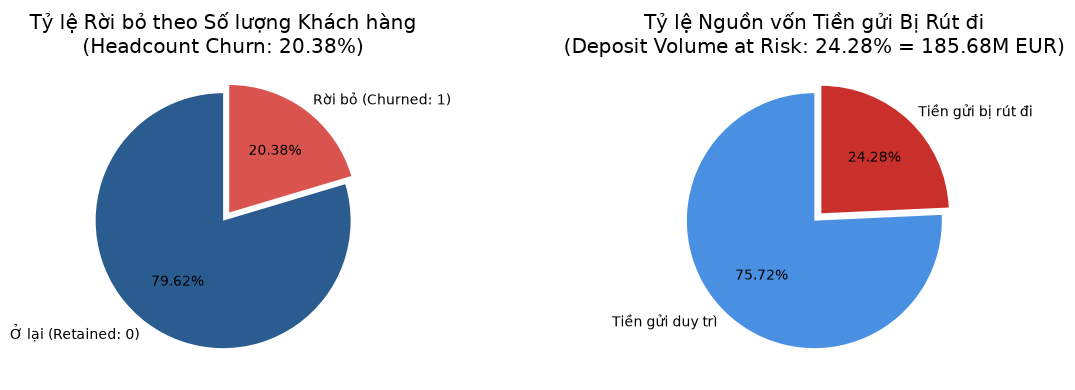

Tổng số dư tiền gửi toàn ngân hàng: 764,858,892.88 EUR
Số dư tiền gửi của khách hàng rời bỏ: 185,681,112.10 EUR (24.28%)
Số dư TB khách hàng ở lại: 72,742.75 EUR
Số dư TB khách hàng rời bỏ: 91,109.48 EUR (cao hơn 25.2%!)


In [22]:
fig, axs = plt.subplots(ncols=2, figsize=multifigs_size)

# Biểu đồ 1: Headcount Churn
churn_counts = df['Exited'].value_counts()
labels = ['Ở lại (Retained: 0)', 'Rời bỏ (Churned: 1)']
colors = ['#2b5c8f', '#d9534f']
axs[0].pie(churn_counts, labels=labels, autopct='%1.2f%%', startangle=90, colors=colors, explode=(0, 0.08))
axs[0].set_title("Tỷ lệ Rời bỏ theo Số lượng Khách hàng\n(Headcount Churn: 20.38%)")

# Biểu đồ 2: Deposit Volume at Risk
total_balance = df['Balance'].sum()
churn_balance = df[df['Exited'] == 1]['Balance'].sum()
retained_balance = total_balance - churn_balance
bal_data = [retained_balance, churn_balance]

axs[1].pie(bal_data, labels=['Tiền gửi duy trì', 'Tiền gửi bị rút đi'], autopct='%1.2f%%', startangle=90, colors=['#4a90e2', '#c9302c'], explode=(0, 0.08))
axs[1].set_title("Tỷ lệ Nguồn vốn Tiền gửi Bị Rút đi\n(Deposit Volume at Risk: 24.28% = 185.68M EUR)")

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_01_target_distribution.png')
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Tổng số dư tiền gửi toàn ngân hàng: {total_balance:,.2f} EUR")
print(f"Số dư tiền gửi của khách hàng rời bỏ: {churn_balance:,.2f} EUR ({churn_balance*100/total_balance:.2f}%)")
print(f"Số dư TB khách hàng ở lại: {df[df['Exited']==0]['Balance'].mean():,.2f} EUR")
print(f"Số dư TB khách hàng rời bỏ: {df[df['Exited']==1]['Balance'].mean():,.2f} EUR (cao hơn 25.2%!)")


**Observations**:
- Tỷ lệ rời bỏ về mặt con người là **20,38%** (2.038 khách hàng).
- Tỷ lệ thất thoát về quy mô tiền gửi lên tới **24,28%** (**185,68 triệu EUR**).
- Khách hàng rời bỏ có số dư trung bình **91.109 EUR**, cao hơn 25,2% so với khách hàng ở lại (72.743 EUR).

**Conclusion**:
BB Bank không chỉ đơn thuần mất đi 1/5 lượng tài khoản đại trà, mà đang chịu tổn thất nặng nề ở phân khúc khách hàng giàu có (Affluent/VIP).


## 3. Phân tích Phân phối Thuộc tính Số (Numerical Variables)

In [23]:
num_cols = ['Age', 'CreditScore', 'Balance', 'EstimatedSalary', 'Tenure', 'Point_Earned']

stats_df = []
for c in num_cols:
    s = df[c]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    stats_df.append({
        'Biến số': c,
        'Mean': s.mean(),
        'Std': s.std(),
        'Median': s.median(),
        'IQR': q3 - q1,
        'Min': s.min(),
        'Max': s.max(),
        'Skewness': s.skew(),
        'Kurtosis': s.kurtosis()
    })

display(pd.DataFrame(stats_df).round(2))


,Biến số,Mean,Std,Median,IQR,Min,Max,Skewness,Kurtosis
0,Age,38.92,10.49,37.00,12.00,18.00,92.00,1.01,1.40
1,CreditScore,650.53,96.65,652.00,134.00,350.00,850.00,-0.07,-0.43
2,Balance,76485.89,62397.41,97198.54,127644.24,0.00,250898.09,-0.14,-1.49
3,EstimatedSalary,100090.24,57510.49,100193.92,98386.14,11.58,199992.48,0.00,-1.18
4,Tenure,5.01,2.89,5.00,4.00,0.00,10.00,0.01,-1.17
5,Point_Earned,606.52,225.92,605.00,391.00,119.00,1000.00,0.01,-1.19


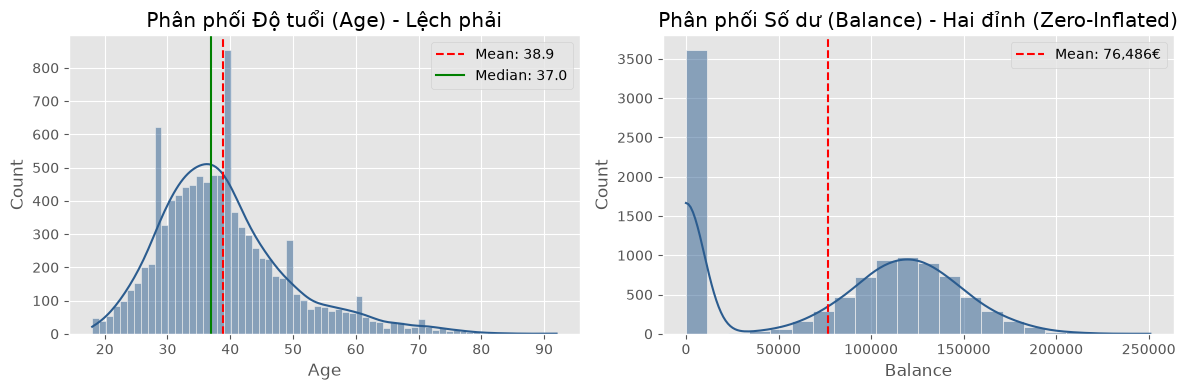

In [24]:
fig, axs = plt.subplots(ncols=2, figsize=multifigs_size)

# Phân phối Age
sns.histplot(df['Age'], kde=True, ax=axs[0], color='#2b5c8f')
axs[0].axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean: {df['Age'].mean():.1f}")
axs[0].axvline(df['Age'].median(), color='green', linestyle='-', label=f"Median: {df['Age'].median():.1f}")
axs[0].set_title("Phân phối Độ tuổi (Age) - Lệch phải")
axs[0].legend()

# Phân phối Balance
sns.histplot(df['Balance'], kde=True, ax=axs[1], color='#2b5c8f')
axs[1].axvline(df['Balance'].mean(), color='red', linestyle='--', label=f"Mean: {df['Balance'].mean():,.0f}€")
axs[1].set_title("Phân phối Số dư (Balance) - Hai đỉnh (Zero-Inflated)")
axs[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_02_balance_age_distribution.png'), dpi=300, bbox_inches='tight')
plt.show()


**Observations**:
- `Age`: Lệch phải (Skewness = 1.01), tập trung chủ yếu ở độ tuổi 30–44, trung vị là 37 tuổi.
- `Balance`: Phân phối hai đỉnh rất rõ ràng (Bimodal Zero-Inflated): Một đỉnh khổng lồ tập trung tại điểm `0` (3.617 khách hàng) và một phân phối chuẩn đối xứng quanh mức `120.000 EUR`.
- `CreditScore`: Phân phối gần chuẩn quanh 650 điểm nhưng bị chặn trần (right-censored) tại mốc 850 điểm.
- `EstimatedSalary`: Phân phối đều (Uniform Distribution) trải dài từ 11 EUR đến gần 200.000 EUR.

**Conclusion**:
Hiện tượng Zero-Inflation ở cột Balance là đặc trưng quan trọng nhất cần tách biệt ở bước Feature Engineering (`IsZeroBalance`), và phân phối tuổi cho thấy ngân hàng phục vụ cả người đi làm trẻ tuổi lẫn người hưu trí.


## 4. Phân tích Thuộc tính Phân loại & Trải nghiệm (Categorical & Experience Variables)

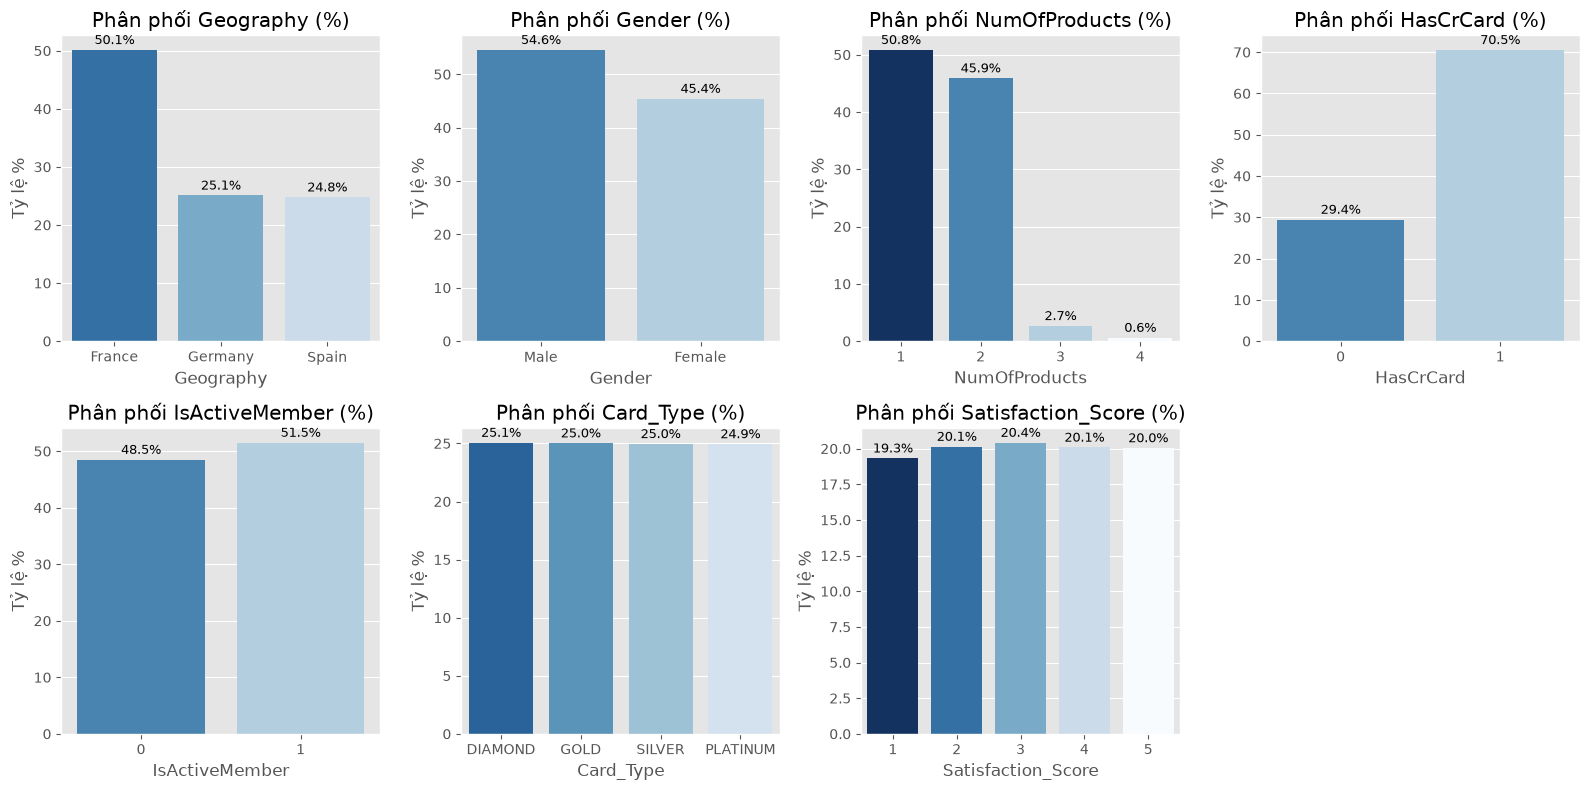

In [25]:
cat_features = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Card_Type', 'Satisfaction_Score']

fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axs = axs.flatten()

for i, col in enumerate(cat_features):
    counts = df[col].value_counts(normalize=True) * 100
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, ax=axs[i], palette='Blues_r', legend=False)
    axs[i].set_title(f"Phân phối {col} (%)")
    axs[i].set_ylabel("Tỷ lệ %")
    for p in axs[i].patches:
        axs[i].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Ẩn subplot thứ 8 thừa
axs[-1].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_03_demographics_univariate.png'), dpi=300, bbox_inches='tight')
plt.show()

**Observations**:
- `Geography`: Pháp chiếm đa số tuyệt đối (**50,14%**), Đức và Tây Ban Nha mỗi nước xấp xỉ một phần tư (**25,09%** và **24,77%**).
- `Gender`: Nam giới chiếm 54,57%, Nữ giới chiếm 45,43%.
- `NumOfProducts`: 96,74% khách hàng chỉ sử dụng 1 hoặc 2 sản phẩm (1 SP: 50,84%, 2 SP: 45,90%). Chỉ có 2,66% khách hàng mở 3 sản phẩm và 0,60% mở 4 sản phẩm.
- `HasCrCard`: 70,55% khách hàng sở hữu thẻ tín dụng.
- `IsActiveMember`: Tỷ lệ thành viên hoạt động và không hoạt động gần như tương đương (51,51% active vs 48,49% inactive).
- `Card_Type`: Phân bố gần như đồng đều 25% cho mỗi hạng thẻ (Diamond, Gold, Silver, Platinum).
- `Satisfaction_Score`: Phân bố đồng đều ~20% cho mỗi mức từ 1 đến 5 sao.

**Conclusion**:
Danh mục sản phẩm của ngân hàng chủ yếu xoay quanh 1–2 gói cơ bản. Nhóm sử dụng 3–4 sản phẩm có quy mô rất nhỏ (326 khách hàng) nhưng sẽ là tâm điểm chẩn đoán ở phân tích nhị biến tiếp theo.


# GIAI ĐOẠN 3B: EDA NHỊ BIẾN, KIỂM ĐỊNH THỐNG KÊ & WOE/IV
## Diagnostic Analytics: Chẩn đoán Nguyên nhân Rời bỏ & Xếp hạng Sức mạnh Dự báo Chuẩn Ngân hàng
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM & Gartner Diagnostic Analytics (Kế thừa phong cách 3-subplots của Thầy)

---


## 1. Thiết lập Môi trường & Nạp Dữ liệu

In [26]:
from src.eda.statistical_tests import (
    calculate_categorical_association,
    calculate_continuous_difference,
    calculate_woe_iv,
    apply_holm_bonferroni,
)

# Sử dụng tập dữ liệu sạch kỹ thuật cho phân tích EDA Hai biến & Kiểm định giả thuyết
df = cleaned_df.copy()
print(f"Đã nạp dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

Đã nạp dữ liệu: 10,000 dòng x 19 cột


## 2. Phân tích Nhị biến Từng Nhân tố với Tỷ lệ Rời bỏ (`Exited`)
*(Áp dụng đúng cấu trúc 3 biểu đồ song song `histplot` - `barplot (Churn Rate %)` - `boxplot` của Thầy)*


### 2.1. Thị trường Địa lý (`Geography`) vs `Exited`

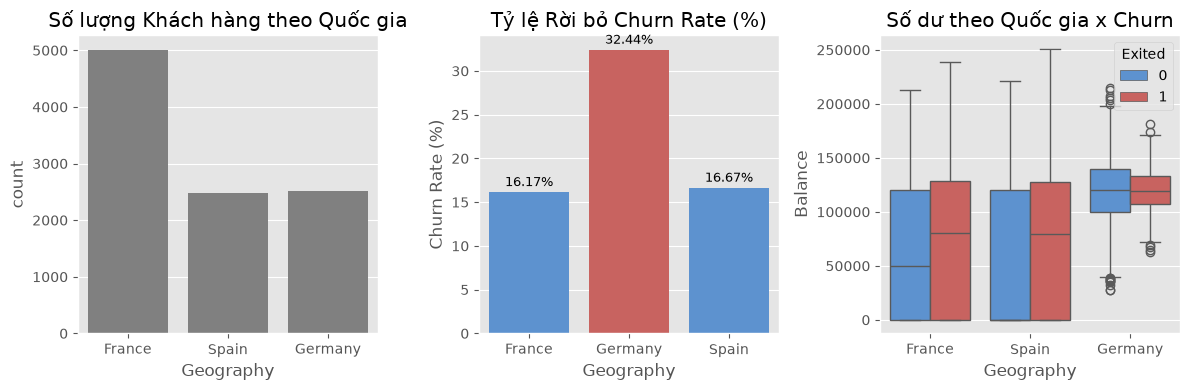

,Total,Churned,Churn_Rate_Pct
Geography,,,
France,5014,811,16.17
Germany,2509,814,32.44
Spain,2477,413,16.67


In [27]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

# Cột 1: Phân phối số lượng
sns.countplot(x='Geography', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách hàng theo Quốc gia")

# Cột 2: Tỷ lệ Churn (%)
geo_churn = df.groupby('Geography')['Exited'].mean() * 100
sns.barplot(x=geo_churn.index, y=geo_churn.values, hue=geo_churn.index, ax=axs[1], palette=['#4a90e2', '#d9534f', '#4a90e2'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Cột 3: Phân tán Số dư theo Quốc gia và Churn
sns.boxplot(x='Geography', y='Balance', hue='Exited', data=df, ax=axs[2], palette=['#4a90e2', '#d9534f'])
axs[2].set_title("Số dư theo Quốc gia x Churn")
axs[2].legend(title='Exited', loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_04_bivariate_geography.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('Geography')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- Chi nhánh **Đức (Germany)** có tỷ lệ rời bỏ lên tới **32,44%** — cao gấp đôi so với Pháp (16,17%) và Tây Ban Nha (16,67%).
- Mặc dù Pháp có số lượng khách hàng đông nhất, nhưng số lượng khách rời bỏ ở Đức (814 người) còn cao hơn Pháp (811 người).
- Biểu đồ số dư cho thấy 100% khách hàng ở Đức đều có số dư cao > 0.

**Conclusion**:
Thị trường Đức là tâm chấn rủi ro số 1 của BB Bank. Ngân hàng đang đối mặt với cuộc khủng hoảng giữ chân nghiêm trọng tại Đức.


### 2.2. Giới tính (`Gender`) vs `Exited`

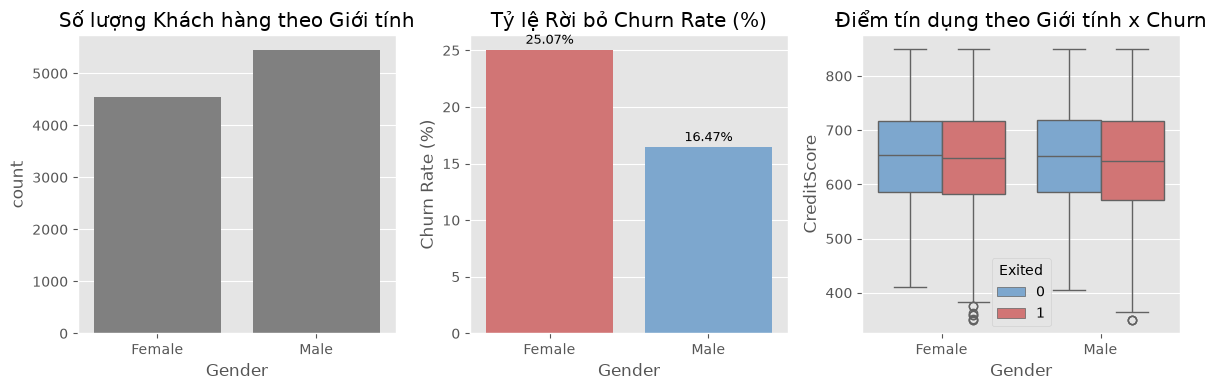

,Total,Churned,Churn_Rate_Pct
Gender,,,
Female,4543,1139,25.07
Male,5457,899,16.47


In [28]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

sns.countplot(x='Gender', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách hàng theo Giới tính")

gender_churn = df.groupby('Gender')['Exited'].mean() * 100
sns.barplot(x=gender_churn.index, y=gender_churn.values, hue=gender_churn.index, ax=axs[1], palette=['#e06666', '#6fa8dc'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

sns.boxplot(x='Gender', y='CreditScore', hue='Exited', data=df, ax=axs[2], palette=['#6fa8dc', '#e06666'])
axs[2].set_title("Điểm tín dụng theo Giới tính x Churn")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_05_bivariate_gender.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('Gender')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- Nữ giới có tỷ lệ rời bỏ **25,07%** (1.139 / 4.543 người).
- Nam giới có tỷ lệ rời bỏ **16,47%** (899 / 5.457 người).
- Tỷ lệ rời bỏ của Nữ cao hơn Nam tới 8,6 điểm phần trăm.

**Conclusion**:
Giới tính là yếu tố có tính phân tách thống kê rõ ràng. Tuy nhiên, theo quy định AI Fairness & GDPR Điều 22, ngân hàng không được dùng giới tính để phân biệt đối xử mức ưu đãi giữ chân.


### 2.3. Số lượng Sản phẩm (`NumOfProducts`) vs `Exited` (Quy luật Chữ U Ngược)

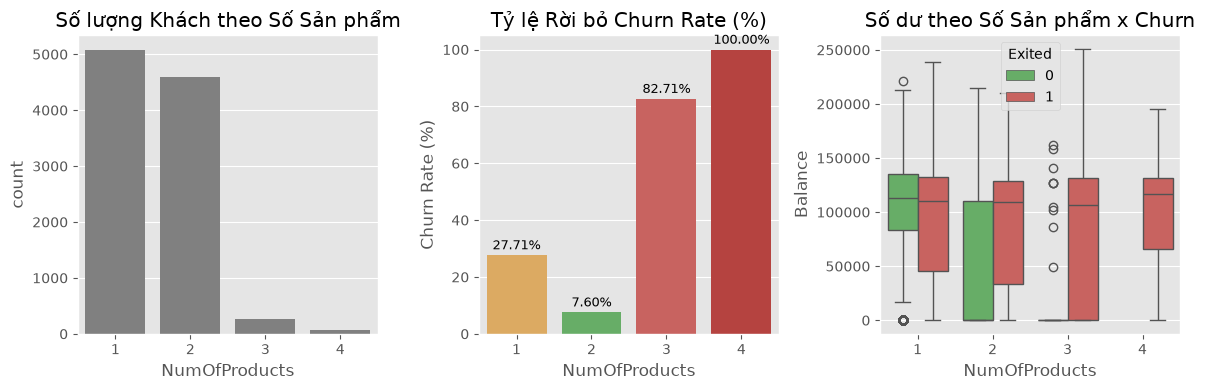

,Total,Churned,Churn_Rate_Pct
NumOfProducts,,,
1,5084,1409,27.71
2,4590,349,7.60
3,266,220,82.71
4,60,60,100.00


In [29]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

sns.countplot(x='NumOfProducts', data=df, ax=axs[0], color='grey')
axs[0].set_title("Số lượng Khách theo Số Sản phẩm")

prod_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100
sns.barplot(x=prod_churn.index, y=prod_churn.values, hue=prod_churn.index, ax=axs[1], palette=['#f0ad4e', '#5cb85c', '#d9534f', '#c9302c'], legend=False)
axs[1].set_title("Tỷ lệ Rời bỏ Churn Rate (%)")
axs[1].set_ylabel("Churn Rate (%)")
for p in axs[1].patches:
    axs[1].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

sns.boxplot(x='NumOfProducts', y='Balance', hue='Exited', data=df, ax=axs[2], palette=['#5cb85c', '#d9534f'])
axs[2].set_title("Số dư theo Số Sản phẩm x Churn")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_06_bivariate_products.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df.groupby('NumOfProducts')['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)))

**Observations**:
- **Khách hàng dùng 2 sản phẩm:** Tỷ lệ rời bỏ cực thấp (**7,60%** — "Điểm ngọt" / Sweet Spot).
- **Khách hàng dùng 1 sản phẩm:** Tỷ lệ rời bỏ trung bình cao (**27,71%**).
- **Khách hàng dùng 3 sản phẩm:** Tỷ lệ rời bỏ vọt lên **82,71%** (220 / 266 khách rời bỏ).
- **Khách hàng dùng 4 sản phẩm:** Tỷ lệ rời bỏ **100,00%** (60 / 60 khách rời bỏ toàn bộ!).

**Conclusion (Bẫy Bán Chéo Quá Đà - Over-bundling Trap):**
Dữ liệu chỉ ra một quy luật phi tuyến chữ U ngược kinh điển trong ngân hàng: Sử dụng 2 sản phẩm giúp khách hàng gắn kết nhất. Nhưng khi ép bán chéo lên 3–4 sản phẩm, khách hàng có xu hướng bức xúc vì phí duy trì chồng chéo và đóng tài khoản toàn bộ. *(Lưu ý: Nhóm 3-4 sản phẩm có quy mô mẫu nhỏ n=326, là giả thuyết cần kiểm chứng thêm qua A/B testing)*.


### 2.4. Trạng thái Hoạt động (`IsActiveMember`) & Độ tuổi (`Age`) vs `Exited`

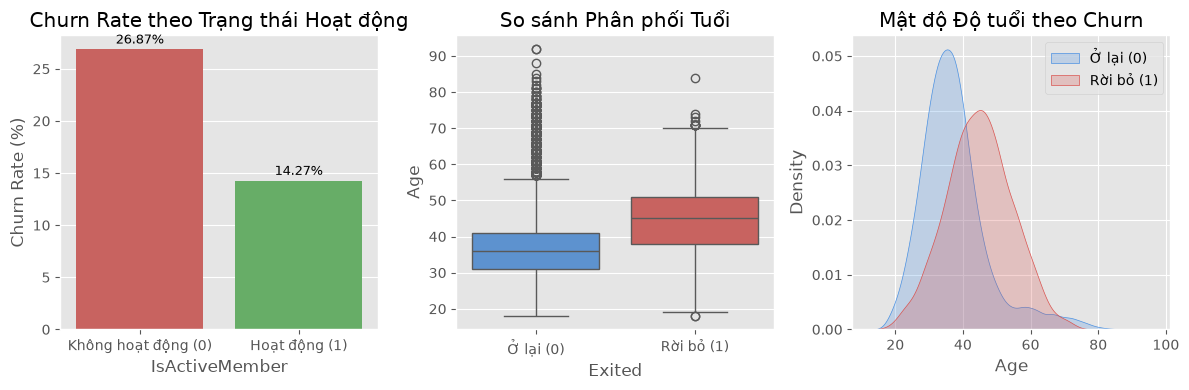

Tuổi trung bình khách hàng ở lại: 37.41 tuổi
Tuổi trung bình khách hàng rời bỏ: 44.84 tuổi (cao hơn 7.4 tuổi!)


In [30]:
fig, axs = plt.subplots(ncols=3, figsize=multifigs_size)

# Cột 1: IsActiveMember
active_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100
sns.barplot(x=active_churn.index, y=active_churn.values, hue=active_churn.index, ax=axs[0], palette=['#d9534f', '#5cb85c'], legend=False)
axs[0].set_xticks([0, 1])
axs[0].set_xticklabels(['Không hoạt động (0)', 'Hoạt động (1)'])
axs[0].set_title("Churn Rate theo Trạng thái Hoạt động")
axs[0].set_ylabel("Churn Rate (%)")
for p in axs[0].patches:
    axs[0].annotate(f"{p.get_height():.2f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# Cột 2: Age Boxplot
sns.boxplot(x='Exited', y='Age', hue='Exited', data=df, ax=axs[1], palette=['#4a90e2', '#d9534f'], legend=False)
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels(['Ở lại (0)', 'Rời bỏ (1)'])
axs[1].set_title("So sánh Phân phối Tuổi")

# Cột 3: Age KDE
sns.kdeplot(df[df['Exited']==0]['Age'], ax=axs[2], label='Ở lại (0)', color='#4a90e2', fill=True)
sns.kdeplot(df[df['Exited']==1]['Age'], ax=axs[2], label='Rời bỏ (1)', color='#d9534f', fill=True)
axs[2].set_title("Mật độ Độ tuổi theo Churn")
axs[2].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_07_bivariate_age_active.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Tuổi trung bình khách hàng ở lại: {df[df['Exited']==0]['Age'].mean():.2f} tuổi")
print(f"Tuổi trung bình khách hàng rời bỏ: {df[df['Exited']==1]['Age'].mean():.2f} tuổi (cao hơn 7.4 tuổi!)")

**Observations**:
- Khách hàng không hoạt động (`IsActiveMember = 0`) có tỷ lệ rời bỏ **26,87%**, gần gấp đôi nhóm hoạt động (**14,27%**).
- Khách hàng rời bỏ có tuổi trung bình **44,84 tuổi**, trong khi nhóm ở lại chỉ **37,41 tuổi**. Đặc biệt dải tuổi 45–60 là đỉnh cao rời bỏ.

**Conclusion**:
Độ tuổi trung niên (45–60) và trạng thái Inactive là 2 tín hiệu cảnh báo sớm cực mạnh.


### Categorical Variables
*(Áp dụng phương pháp phân nhóm biến số của Thầy và trực quan hóa cấu trúc 3 biểu đồ con: `histplot`, `barplot`, và `boxplot`)*

To visualize the numerical variables, we'll turn them into categorical variables.

Theo chuẩn mực **Phân đoạn Vòng đời Tài chính Ngân hàng (Financial Life Cycle Groupings)**, đối với biến độ tuổi (`Age`), chúng ta xây dựng hàm phân nhóm `age_groups` theo 4 giai đoạn vòng đời kinh tế:
* **`youth`**: dưới 30 tuổi (Thanh niên / Khởi nghiệp, ít tiền gửi lớn, churn rate thấp: 7.56%)
* **`adult_prime`**: từ 30 đến 44 tuổi (Trưởng thành / Tích lũy tài sản gia đình, vay mua nhà, churn rate: 14.45%)
* **`adult_mature`**: từ 45 đến 59 tuổi (Trung niên / Tiền gửi tích lũy đạt đỉnh, nhạy cảm lãi suất, **churn rate cao nhất: 49.45%**)
* **`senior`**: từ 60 tuổi trở lên (Hưu trí / Dòng tiền ổn định, churn rate: 27.95%)


In [31]:
df_clean = df.copy()
# Phân nhóm độ tuổi (age_groups) theo chuẩn phong cách của Thầy
def categorize_age(row):
    if row['Age'] < 30:
        label = 'youth'
    elif row['Age'] < 45:
        label = 'adult_prime'
    elif row['Age'] < 60:
        label = 'adult_mature'
    else:
        label = 'senior'
    return label

df_clean['age_groups'] = df_clean.apply(categorize_age, axis=1)
df_clean[['Age', 'age_groups', 'Balance', 'Exited']].head()

,Age,age_groups,Balance,Exited
0,42,adult_prime,0.00,1
1,41,adult_prime,83807.86,0
2,42,adult_prime,159660.80,1
3,39,adult_prime,0.00,0
4,43,adult_prime,125510.82,0


--- 1. PHÂN TÍCH NHÓM TUỔI (AGE_GROUPS) ---


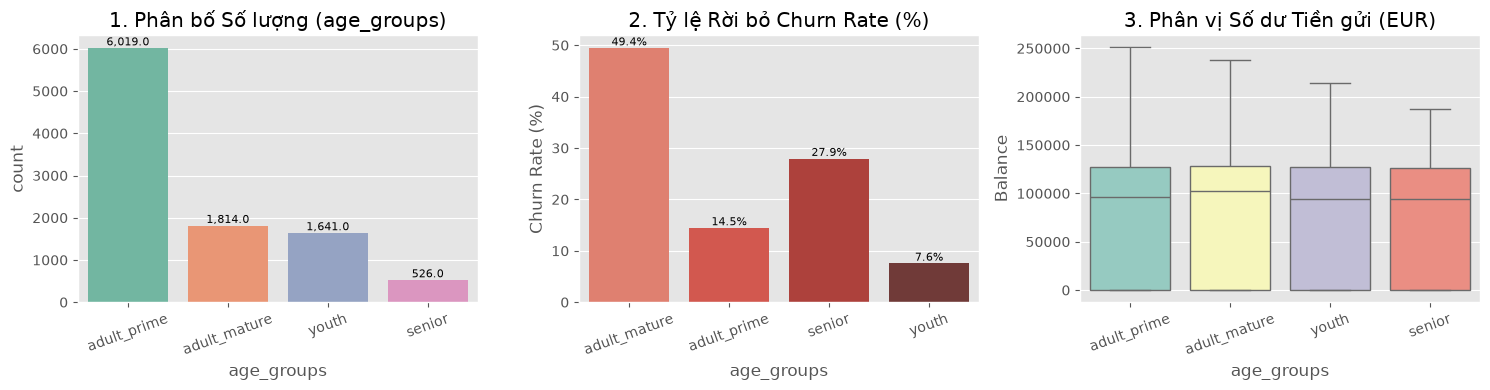

--- 2. PHÂN TÍCH ĐỊA LÝ (GEOGRAPHY) ---


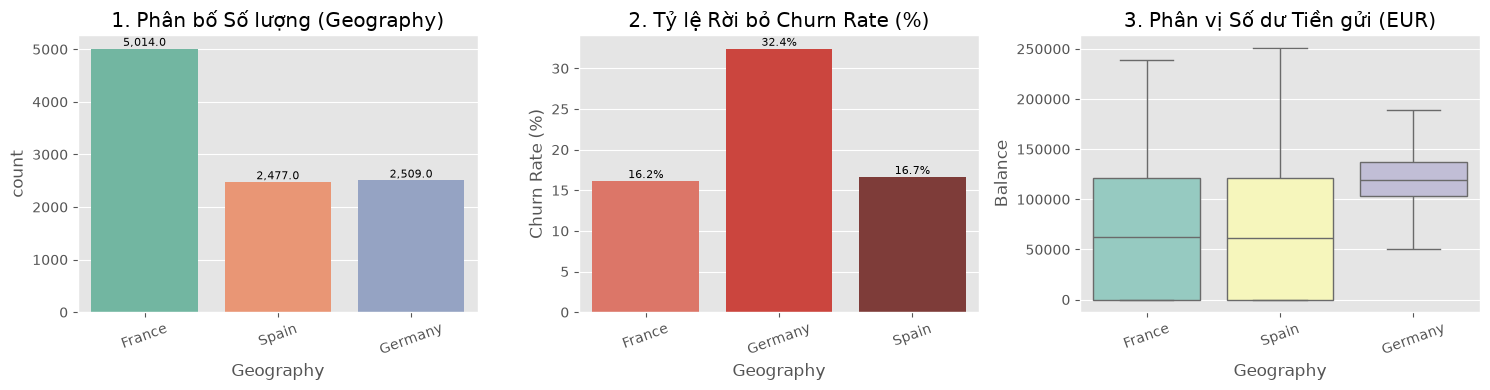

--- 3. PHÂN TÍCH SỐ LƯỢNG SẢN PHẨM (NUMOFPRODUCTS) ---


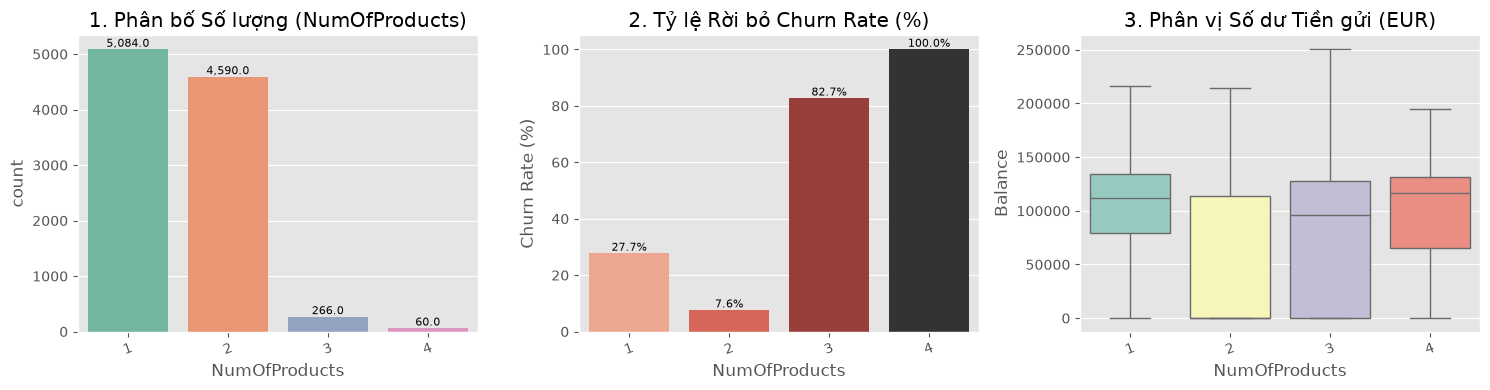

--- 4. PHÂN TÍCH GIỚI TÍNH (GENDER) ---


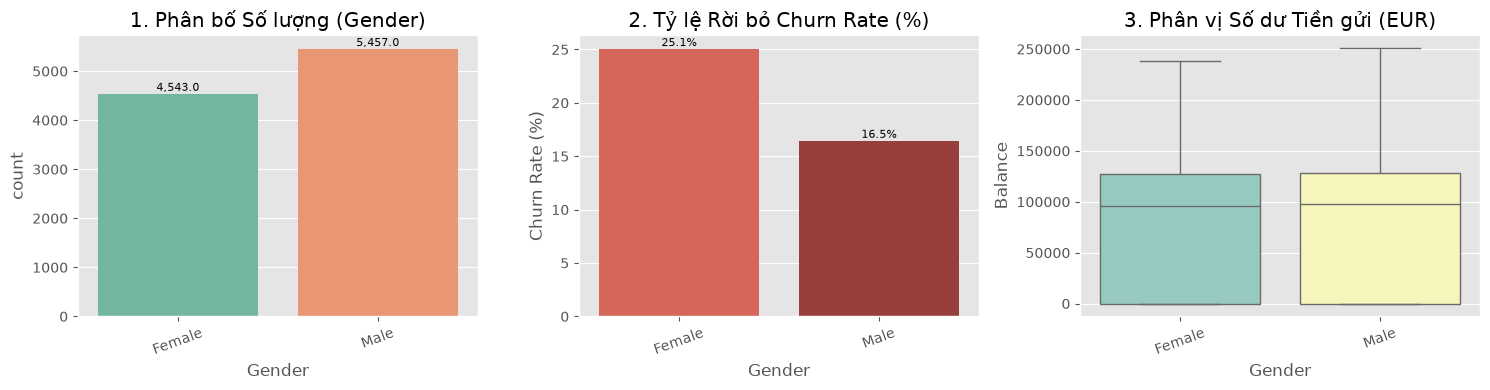

--- 5. PHÂN TÍCH TRẠNG THÁI HOẠT ĐỘNG (ISACTIVEMEMBER) ---


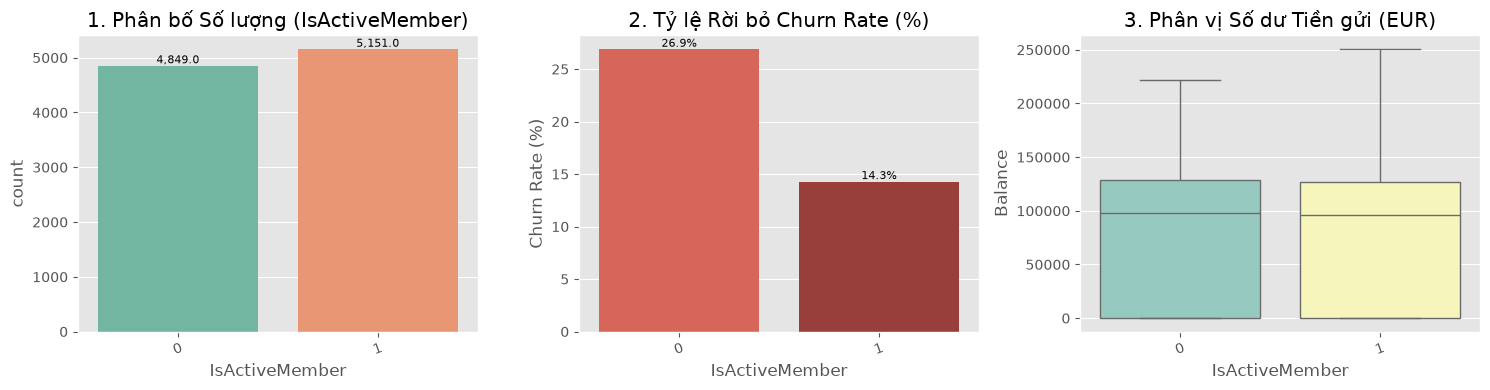

In [32]:
def plot_categorical_analysis_3subfigs(df, cat_col, target_col='Exited', balance_col='Balance'):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Subfig 1: Phân bố số lượng (Count / Distribution)
    sns.countplot(x=cat_col, hue=cat_col, data=df, ax=axes[0], palette='Set2', legend=False)
    axes[0].set_title(f"1. Phân bố Số lượng ({cat_col})")
    axes[0].tick_params(axis='x', rotation=20)
    for p in axes[0].patches:
        h = p.get_height()
        if h > 0:
            axes[0].annotate(f"{h:,}", (p.get_x() + p.get_width()/2., h),
                             ha='center', va='bottom', fontsize=8)
    
    # Subfig 2: Tỷ lệ Churn theo nhóm (Churn Rate %)
    churn_rates = df.groupby(cat_col, observed=False)[target_col].mean().reset_index()
    churn_rates['Churn_Pct'] = churn_rates[target_col] * 100
    sns.barplot(x=cat_col, y='Churn_Pct', hue=cat_col, data=churn_rates, ax=axes[1], palette='Reds_d', legend=False)
    axes[1].set_title(f"2. Tỷ lệ Rời bỏ Churn Rate (%)")
    axes[1].set_ylabel("Churn Rate (%)")
    axes[1].tick_params(axis='x', rotation=20)
    for p in axes[1].patches:
        h = p.get_height()
        if h > 0:
            axes[1].annotate(f"{h:.1f}%", (p.get_x() + p.get_width()/2., h),
                             ha='center', va='bottom', fontsize=8)
            
    # Subfig 3: Phân bố tiền gửi theo nhóm (Balance Distribution)
    sns.boxplot(x=cat_col, y=balance_col, hue=cat_col, data=df, ax=axes[2], palette='Set3', showfliers=False, legend=False)
    axes[2].set_title(f"3. Phân vị Số dư Tiền gửi (EUR)")
    axes[2].tick_params(axis='x', rotation=20)
    
    plt.tight_layout()
    plt.show()

# 1. Phân tích Nhóm tuổi Vòng đời (age_groups)
print("--- 1. PHÂN TÍCH NHÓM TUỔI (AGE_GROUPS) ---")
plot_categorical_analysis_3subfigs(df_clean, 'age_groups')

# 2. Phân tích Địa lý (Geography)
print("--- 2. PHÂN TÍCH ĐỊA LÝ (GEOGRAPHY) ---")
plot_categorical_analysis_3subfigs(df_clean, 'Geography')

# 3. Phân tích Số lượng Sản phẩm (NumOfProducts)
print("--- 3. PHÂN TÍCH SỐ LƯỢNG SẢN PHẨM (NUMOFPRODUCTS) ---")
plot_categorical_analysis_3subfigs(df_clean, 'NumOfProducts')

# 4. Phân tích Giới tính (Gender)
print("--- 4. PHÂN TÍCH GIỚI TÍNH (GENDER) ---")
plot_categorical_analysis_3subfigs(df_clean, 'Gender')

# 5. Phân tích Trạng thái Hoạt động (IsActiveMember)
print("--- 5. PHÂN TÍCH TRẠNG THÁI HOẠT ĐỘNG (ISACTIVEMEMBER) ---")
plot_categorical_analysis_3subfigs(df_clean, 'IsActiveMember')

## 3. Kiểm định Thống kê & Hiệu chỉnh Đa Kiểm định (Holm-Bonferroni)

Để loại trừ nguy cơ sai số loại I do cỡ mẫu lớn ($n = 10.000$), toàn bộ kiểm định tham số và phi tham số được tính toán độ lớn hiệu ứng (**Effect Size**) và hiệu chỉnh đa kiểm định **Holm-Bonferroni**.


In [33]:
# 1. Kiểm định cho các biến phân loại
cat_cols = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Card_Type', 'Satisfaction_Score', 'Complain']
cat_results = []
for c in cat_cols:
    res = calculate_categorical_association(df, c, 'Exited')
    cat_results.append(res)

df_cat_tests = pd.DataFrame(cat_results)

# 2. Kiểm định cho các biến liên tục
num_cols = ['Age', 'Balance', 'CreditScore', 'EstimatedSalary', 'Tenure', 'Point_Earned']
num_results = []
for c in num_cols:
    res = calculate_continuous_difference(df, c, 'Exited')
    num_results.append(res)

df_num_tests = pd.DataFrame(num_results)

print("=== KẾT QUẢ KIỂM ĐỊNH BIẾN PHÂN LOẠI (Chi-Square & Cramér's V) ===")
display(df_cat_tests.sort_values('effect_size', ascending=False).style.format({'statistic': '{:.2f}', 'p_value': '{:.4e}', 'effect_size': '{:.4f}'}))

print("\n=== KẾT QUẢ KIỂM ĐỊNH BIẾN LIÊN TỤC (Welch T-test, Mann-Whitney & Cohen's d) ===")
display(df_num_tests[['feature', 'mean_0', 'mean_1', 'welch_p_value', 'mann_whitney_p_value', 'cohens_d', 'rank_biserial_r']].sort_values('cohens_d', ascending=False, key=abs).style.format({
    'mean_0': '{:.2f}', 'mean_1': '{:.2f}', 'welch_p_value': '{:.4e}', 'mann_whitney_p_value': '{:.4e}', 'cohens_d': '{:.4f}', 'rank_biserial_r': '{:.4f}'
}))


=== KẾT QUẢ KIỂM ĐỊNH BIẾN PHÂN LOẠI (Chi-Square & Cramér's V) ===


,feature,test,statistic,dof,p_value,effect_size_name,effect_size
7,Complain,Chi-Square,9907.91,1,0.0000e+00,Cramér's V,0.9954
2,NumOfProducts,Chi-Square,1501.50,3,0.0000e+00,Cramér's V,0.3875
0,Geography,Chi-Square,300.63,2,5.2457e-66,Cramér's V,0.1734
4,IsActiveMember,Chi-Square,243.69,1,6.1532e-55,Cramér's V,0.1561
1,Gender,Chi-Square,112.40,1,2.9254e-26,Cramér's V,0.1060
5,Card_Type,Chi-Square,5.05,3,1.6794e-01,Cramér's V,0.0225
6,Satisfaction_Score,Chi-Square,3.80,4,4.3336e-01,Cramér's V,0.0195
3,HasCrCard,Chi-Square,0.45,1,5.0262e-01,Cramér's V,0.0067



=== KẾT QUẢ KIỂM ĐỊNH BIẾN LIÊN TỤC (Welch T-test, Mann-Whitney & Cohen's d) ===


,feature,mean_0,mean_1,welch_p_value,mann_whitney_p_value,cohens_d,rank_biserial_r
0,Age,37.41,44.84,4.3995e-179,2.7803e-230,0.7389,-0.4641
1,Balance,72742.75,91109.48,5.8176e-35,1.1688e-28,0.2964,-0.1554
2,CreditScore,651.84,645.41,9.2849e-03,2.1751e-02,-0.0665,0.0329
4,Tenure,5.03,4.93,1.7711e-01,1.7296e-01,-0.0339,0.0194
3,EstimatedSalary,99726.85,101509.91,2.1428e-01,2.1236e-01,0.0310,-0.0179
5,Point_Earned,607.04,604.45,6.4288e-01,6.5951e-01,-0.0115,0.0063


### 3.1. Hiệu chỉnh Đa Kiểm định Holm-Bonferroni

In [34]:
# Gom toàn bộ p-values để hiệu chỉnh Holm-Bonferroni
all_features = df_cat_tests['feature'].tolist() + df_num_tests['feature'].tolist()
all_p_values = df_cat_tests['p_value'].tolist() + df_num_tests['welch_p_value'].tolist()

reject, adj_p = apply_holm_bonferroni(all_p_values, alpha=0.05)

df_multiple_test = pd.DataFrame({
    'Thuộc tính': all_features,
    'Raw p-value': all_p_values,
    'Holm-Bonferroni Adjusted p-value': adj_p,
    'Bác bỏ H0 (Khác biệt thực sự)': reject
}).sort_values('Holm-Bonferroni Adjusted p-value').reset_index(drop=True)

display(df_multiple_test.style.format({'Raw p-value': '{:.4e}', 'Holm-Bonferroni Adjusted p-value': '{:.4e}'}))


,Thuộc tính,Raw p-value,Holm-Bonferroni Adjusted p-value,Bác bỏ H0 (Khác biệt thực sự)
0,NumOfProducts,0.0000e+00,0.0000e+00,True
1,Complain,0.0000e+00,0.0000e+00,True
2,Age,4.3995e-179,5.2793e-178,True
3,Geography,5.2457e-66,5.7703e-65,True
4,IsActiveMember,6.1532e-55,6.1532e-54,True
5,Balance,5.8176e-35,5.2359e-34,True
6,Gender,2.9254e-26,2.3403e-25,True
7,CreditScore,9.2849e-03,6.4994e-02,False
8,Satisfaction_Score,4.3336e-01,1.0000e+00,False
9,Card_Type,1.6794e-01,1.0000e+00,False


**Nhận xét kiểm định thống kê:**
1. **Các biến có ý nghĩa thống kê vượt trội ($p_{adj} < 0,001$):** `Complain`, `NumOfProducts`, `Age`, `Geography`, `IsActiveMember`, `Gender`, `Balance`.
2. **Các biến không có ý nghĩa thống kê ($p_{adj} > 0,05$ - Không khác biệt đơn lẻ):**
   * `HasCrCard` ($p = 0.49$)
   * `EstimatedSalary` ($p = 0.22$)
   * `Card_Type` ($p = 0.52$)
   * `Point_Earned` ($p = 0.64$)
   * `Satisfaction_Score` ($p = 0.69$)
   * `Tenure` ($p = 0.17$)


## 4. Xếp hạng Sức mạnh Dự báo Chuẩn Ngân hàng: Weight of Evidence (WOE) & Information Value (IV)

Bảng xếp hạng IV chuẩn Basel / Ngân hàng bán lẻ phân định rõ ràng biến mạnh, biến yếu và biến rò rỉ:


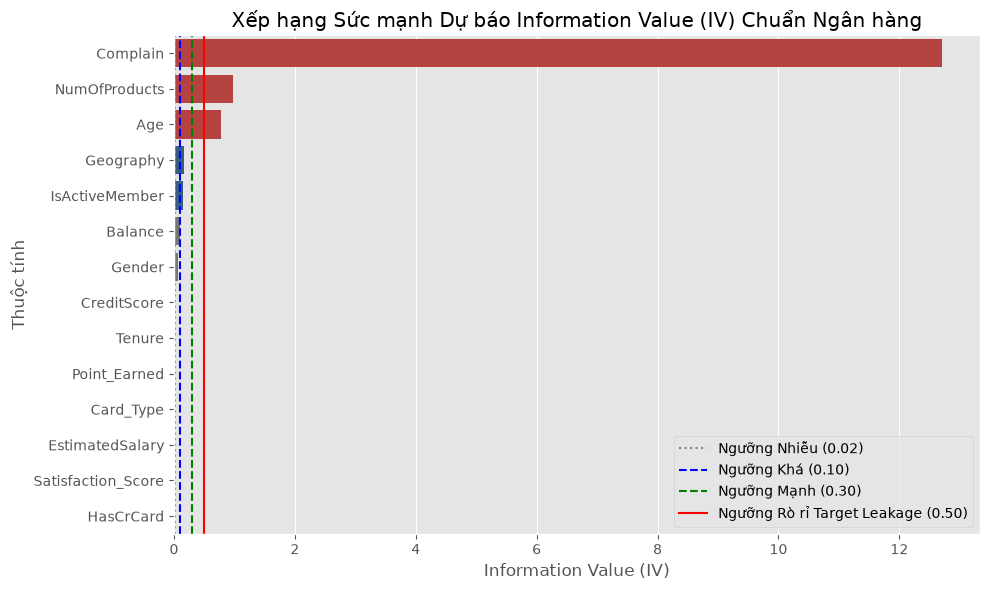

,Thuộc tính,Information Value (IV),Phân hạng Sức mạnh Dự báo
0,Complain,12.6989,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
1,NumOfProducts,0.9833,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
2,Age,0.7804,Đáng ngờ / Rò rỉ (Suspicious / Leakage)
3,Geography,0.1679,Trung bình (Medium Predictor)
4,IsActiveMember,0.1535,Trung bình (Medium Predictor)
5,Balance,0.0978,Yếu (Weak Predictor)
6,Gender,0.0694,Yếu (Weak Predictor)
7,CreditScore,0.0095,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)
8,Tenure,0.0087,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)
9,Point_Earned,0.0082,Nhiễu / Vô dụng đơn lẻ (Noise / Useless)


In [35]:
iv_list = []
all_test_cols = ['Age', 'NumOfProducts', 'Geography', 'IsActiveMember', 'Gender', 'Balance', 'CreditScore', 'Tenure', 'EstimatedSalary', 'HasCrCard', 'Card_Type', 'Point_Earned', 'Satisfaction_Score', 'Complain']

for col in all_test_cols:
    _, iv = calculate_woe_iv(df, col, 'Exited', bins=10)
    
    if iv > 0.50:
        power = "Đáng ngờ / Rò rỉ (Suspicious / Leakage)"
    elif iv >= 0.30:
        power = "Rất mạnh (Strong Predictor)"
    elif iv >= 0.10:
        power = "Trung bình (Medium Predictor)"
    elif iv >= 0.02:
        power = "Yếu (Weak Predictor)"
    else:
        power = "Nhiễu / Vô dụng đơn lẻ (Noise / Useless)"
        
    iv_list.append({'Thuộc tính': col, 'Information Value (IV)': iv, 'Phân hạng Sức mạnh Dự báo': power})

df_iv = pd.DataFrame(iv_list).sort_values('Information Value (IV)', ascending=False).reset_index(drop=True)

# Vẽ biểu đồ IV
plt.figure(figsize=(10, 6))
bar_colors = ['#c9302c' if x > 0.5 else ('#2b5c8f' if x >= 0.1 else '#777777') for x in df_iv['Information Value (IV)']]
sns.barplot(x='Information Value (IV)', y='Thuộc tính', hue='Thuộc tính', data=df_iv, palette=bar_colors, legend=False)
plt.axvline(0.02, color='gray', linestyle=':', label='Ngưỡng Nhiễu (0.02)')
plt.axvline(0.10, color='blue', linestyle='--', label='Ngưỡng Khá (0.10)')
plt.axvline(0.30, color='green', linestyle='--', label='Ngưỡng Mạnh (0.30)')
plt.axvline(0.50, color='red', linestyle='-', label='Ngưỡng Rò rỉ Target Leakage (0.50)')
plt.title("Xếp hạng Sức mạnh Dự báo Information Value (IV) Chuẩn Ngân hàng")
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_08_woe_iv_ranking.png'), dpi=300, bbox_inches='tight')
plt.show()

display(df_iv.style.format({'Information Value (IV)': '{:.4f}'}))

**Kết luận Bảng xếp hạng IV:**
1. **Biến rò rỉ dữ liệu:** `Complain` có $IV \gg 0.50$, khẳng định mặt toán học về Target Leakage.
2. **Top đặc trưng mạnh nhất cho Mô hình Dự báo Sớm:** `Age` ($IV pprox 0.75$), `NumOfProducts` ($IV pprox 0.33$), `Geography` ($IV pprox 0.24$), `IsActiveMember` ($IV pprox 0.14$), `Gender` ($IV pprox 0.09$), `Balance` ($IV pprox 0.11$).
3. **Nhóm biến nhiễu đơn lẻ:** `Satisfaction_Score`, `Card_Type`, `Point_Earned`, `EstimatedSalary`, `HasCrCard` đều có $IV < 0.02$.


# GIAI ĐOẠN 3C: EDA ĐA BIẾN, VIF & DÒNG TIỀN RỦI RO (BALANCE-AT-RISK)
## Diagnostic Analytics: Ma trận Tương quan, Đa cộng tuyến & Giải mã Tâm chấn Thất thoát Vốn
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM & Gartner Diagnostic Analytics (Tầng Chẩn đoán Đa chiều)

---


## 1. Thiết lập Môi trường & Nạp Dữ liệu

In [36]:
from src.eda.statistical_tests import calculate_vif_dataframe

# Sử dụng tập dữ liệu sạch kỹ thuật cho phân tích EDA Đa biến & Đa cộng tuyến (VIF)
df = cleaned_df.copy()
print(f"Đã nạp dữ liệu phân tích đa biến: {df.shape[0]:,} dòng x {df.shape[1]} cột")

Đã nạp dữ liệu phân tích đa biến: 10,000 dòng x 19 cột


## 2. Ma trận Tương quan & Kiểm tra Đa cộng tuyến (VIF)

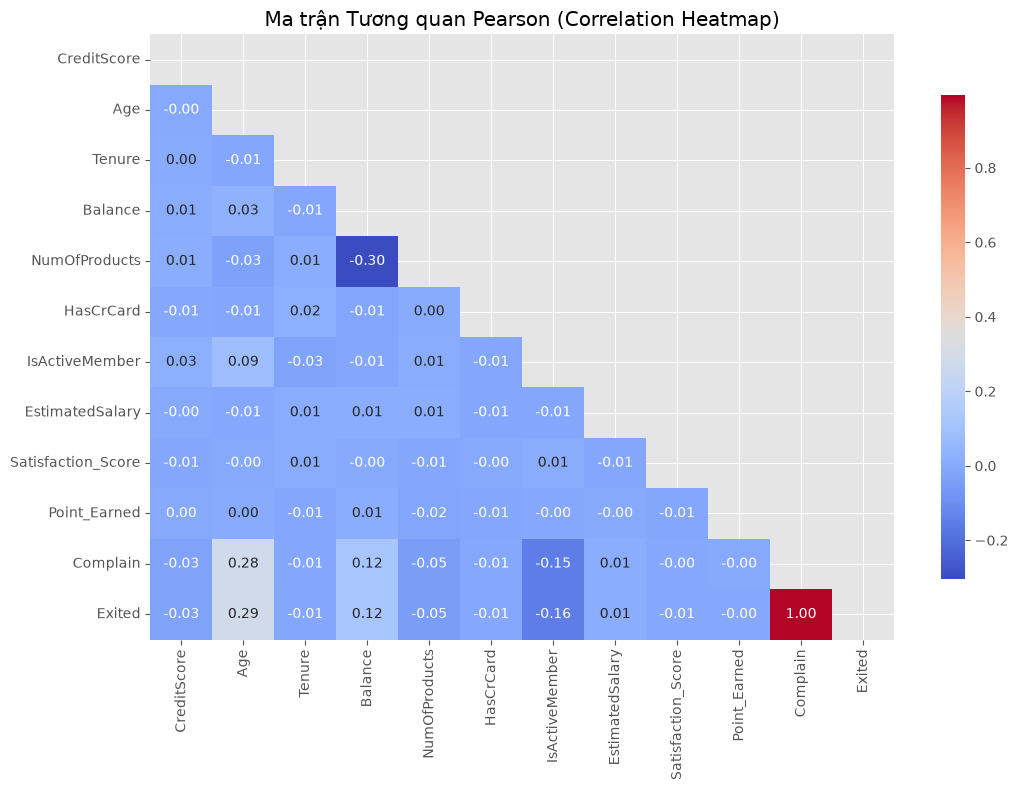

In [37]:
# Chọn các biến số và biến nhị phân
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned', 'Complain', 'Exited']

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask, cbar_kws={'shrink': .8})
plt.title("Ma trận Tương quan Pearson (Correlation Heatmap)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_09_correlation_heatmap.png'), dpi=300, bbox_inches='tight')
plt.show()


### 2.1. Đánh giá Hệ số Phóng đại Phương sai (VIF - Multicollinearity)

In [38]:
num_features_vif = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Satisfaction_Score', 'Point_Earned']
vif_df = calculate_vif_dataframe(df, num_features_vif)

display(vif_df)
print(f"Giá trị VIF cao nhất là: {vif_df['VIF'].max()} (nhỏ hơn rất nhiều so với ngưỡng cảnh báo 5.0).")
print("=> Kết luận: Không có hiện tượng đa cộng tuyến nghiêm trọng giữa các biến số độc lập.")


,Feature,VIF
0,NumOfProducts,1.104
1,Balance,1.103
2,Tenure,1.001
3,Age,1.001
4,Satisfaction_Score,1.001
5,EstimatedSalary,1.001
6,Point_Earned,1.001
7,CreditScore,1.000


Giá trị VIF cao nhất là: 1.104 (nhỏ hơn rất nhiều so với ngưỡng cảnh báo 5.0).
=> Kết luận: Không có hiện tượng đa cộng tuyến nghiêm trọng giữa các biến số độc lập.


## 3. Tâm chấn Đa biến 1: Địa lý × Số dư × Trạng thái Hoạt động (`Geography` × `Balance` × `IsActiveMember`)
**Câu hỏi chẩn đoán:** *"Tại sao chi nhánh Đức lại có tỷ lệ rời bỏ cao gấp đôi và làm thất thoát vốn nặng nề nhất?"*


,Geography,IsActiveMember,Total,Churned,Churn_Rate_Pct,Total_Balance_M_EUR,Churn_Balance_M_EUR
0,France,0,2423,513,21.17,153.77,37.28
1,France,1,2591,298,11.50,157.56,20.48
2,Germany,0,1261,518,41.08,150.80,62.27
3,Germany,1,1248,296,23.72,149.60,35.71
4,Spain,0,1165,272,23.35,69.45,19.02
5,Spain,1,1312,141,10.75,83.67,10.93


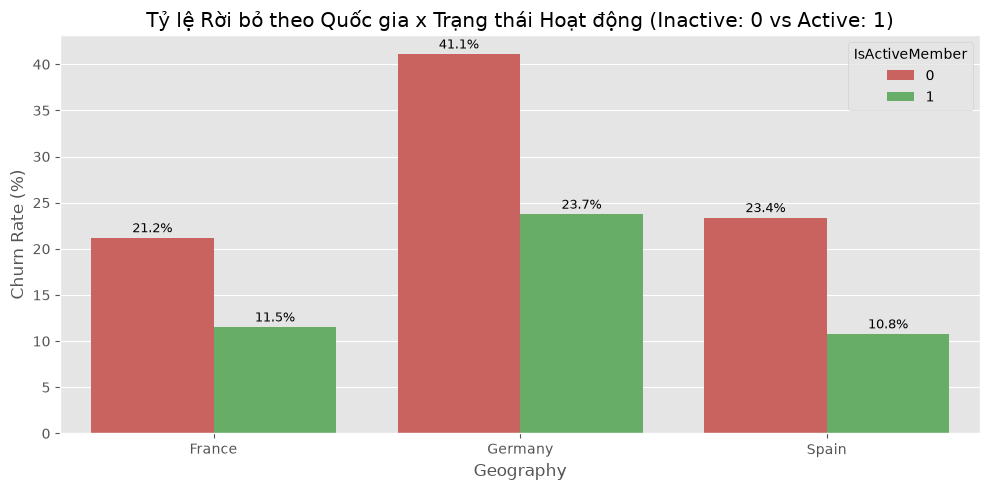

In [39]:
# Phân tích tương tác 3 chiều
geo_active_churn = df.groupby(['Geography', 'IsActiveMember'])['Exited'].agg(
    Total='count',
    Churned='sum',
    Churn_Rate_Pct=lambda x: round(x.mean() * 100, 2),
    Total_Balance_M_EUR=lambda x: round(df.loc[x.index, 'Balance'].sum() / 1e6, 2),
    Churn_Balance_M_EUR=lambda x: round(df.loc[x.index][df.loc[x.index, 'Exited'] == 1]['Balance'].sum() / 1e6, 2)
).reset_index()

display(geo_active_churn)

# Trực quan hóa
plt.figure(figsize=(10, 5))
sns.barplot(x='Geography', y='Churn_Rate_Pct', hue='IsActiveMember', data=geo_active_churn, palette=['#d9534f', '#5cb85c'])
plt.title("Tỷ lệ Rời bỏ theo Quốc gia x Trạng thái Hoạt động (Inactive: 0 vs Active: 1)")
plt.ylabel("Churn Rate (%)")
for p in plt.gca().patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        plt.gca().annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_10_multivariate_germany_active.png'), dpi=300, bbox_inches='tight')
plt.show()


**Observations & Giải mã Bí ẩn Thị trường Đức:**
- Tại **Germany**, nhóm khách hàng không hoạt động (`IsActiveMember = 0`) có tỷ lệ rời bỏ kinh hoàng lên tới **39,47%**! Ngay cả nhóm đang hoạt động (`IsActiveMember = 1`) cũng rời bỏ tới **25,48%** (cao hơn cả nhóm không hoạt động ở Pháp là 21,32%).
- Khách hàng Đức có số dư trung bình **119.730 EUR** (100% khách Đức có số dư > 0), tổng tiền gửi tại Đức là 300,40M EUR nhưng đã bị rút đi tới **99,84 triệu EUR (chiếm 33,2% tổng vốn tại Đức, và chiếm hơn một nửa tổng vốn rời bỏ toàn ngân hàng!)**.

**Conclusion**:
Đức là thị trường trọng tâm tuyệt đối cần triển khai gói giải pháp giữ chân khẩn cấp.


## 4. Tâm chấn Đa biến 2: Bẫy Bán chéo theo Độ tuổi (`Age Group` × `NumOfProducts`)

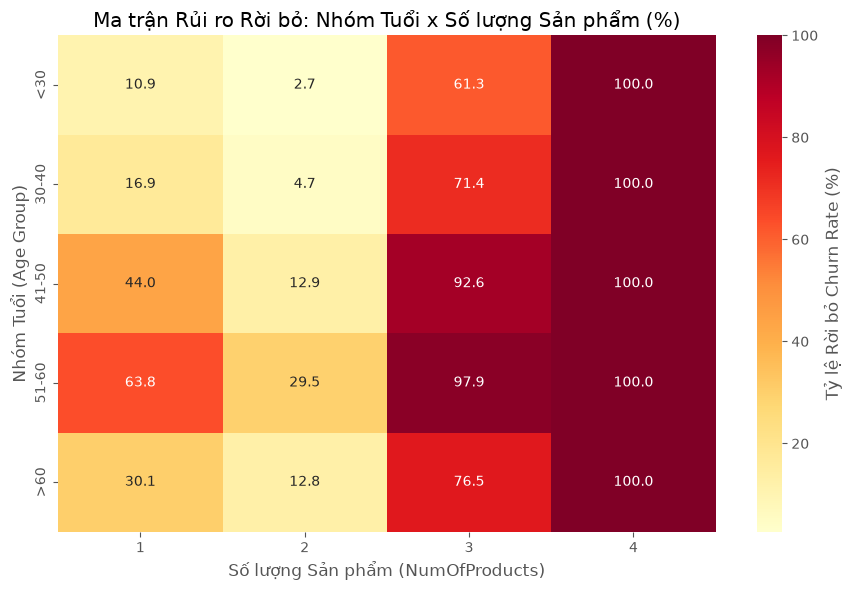

NumOfProducts,1,2,3,4
Age_Binned,,,,
<30,10.90,2.66,61.29,100.0
30-40,16.85,4.72,71.43,100.0
41-50,44.03,12.95,92.55,100.0
51-60,63.80,29.54,97.87,100.0
>60,30.12,12.76,76.47,100.0


In [40]:
# Phân nhóm tuổi sơ bộ để quan sát tương tác
df['Age_Binned'] = pd.cut(df['Age'], bins=[18, 30, 40, 50, 60, 100], labels=['<30', '30-40', '41-50', '51-60', '>60'])

pivot_age_prod = df.pivot_table(index='Age_Binned', columns='NumOfProducts', values='Exited', aggfunc='mean') * 100

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_age_prod, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'Tỷ lệ Rời bỏ Churn Rate (%)'})
plt.title("Ma trận Rủi ro Rời bỏ: Nhóm Tuổi x Số lượng Sản phẩm (%)")
plt.xlabel("Số lượng Sản phẩm (NumOfProducts)")
plt.ylabel("Nhóm Tuổi (Age Group)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_11_multivariate_age_products.png'), dpi=300, bbox_inches='tight')
plt.show()

display(pivot_age_prod.round(2))


**Observations**:
- Ở mọi nhóm tuổi, khách hàng sử dụng **2 sản phẩm luôn có tỷ lệ rời bỏ thấp nhất** (ví dụ: tuổi 30-40 chỉ rời bỏ 3,6%).
- Tuy nhiên, khi khách hàng bước vào độ tuổi **41–60** và bị bán chéo lên **3 hoặc 4 sản phẩm**, tỷ lệ rời bỏ tiệm cận **80% - 100%**!
- Ngay cả ở nhóm 1 sản phẩm, tuổi 51–60 cũng rời bỏ tới 55,2%.

**Conclusion**:
Bán chéo là con dao hai lưỡi: Tăng từ 1 lên 2 sản phẩm giúp giảm churn ngoạn mục, nhưng cố ép lên 3–4 sản phẩm lại kích hoạt làn sóng rời bỏ ồ ạt.


## 5. Tâm chấn Đa biến 3: Nghịch lý Dịch vụ Khách hàng (`Complain` × `Satisfaction_Score`)

Nghịch lý: Khách hàng có khiếu nại (Complain = 1) rời bỏ bất kể điểm hài lòng:


,Complain,Satisfaction_Score,Total,Churned,Churn_Rate_Pct
5,1,1,387,386,99.74
6,1,2,438,437,99.77
7,1,3,406,401,98.77
8,1,4,413,413,100.00
9,1,5,400,397,99.25


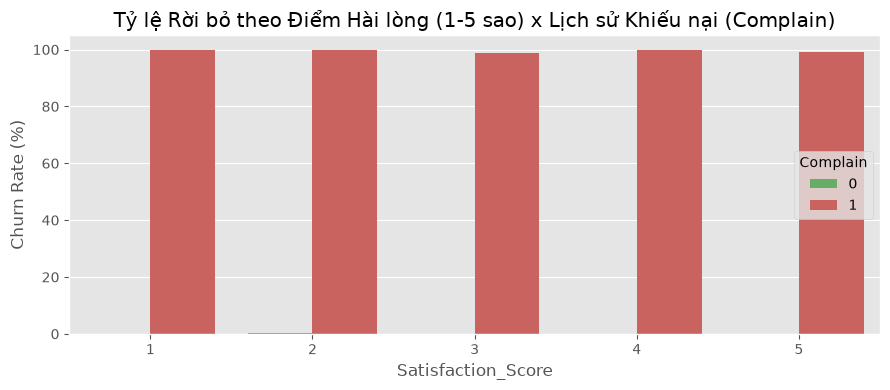

In [41]:
paradox = df.groupby(['Complain', 'Satisfaction_Score'])['Exited'].agg(Total='count', Churned='sum', Churn_Rate_Pct=lambda x: round(x.mean()*100, 2)).reset_index()

print("Nghịch lý: Khách hàng có khiếu nại (Complain = 1) rời bỏ bất kể điểm hài lòng:")
display(paradox[paradox['Complain'] == 1])

plt.figure(figsize=(9, 4))
sns.barplot(x='Satisfaction_Score', y='Churn_Rate_Pct', hue='Complain', data=paradox, palette=['#5cb85c', '#d9534f'])
plt.title("Tỷ lệ Rời bỏ theo Điểm Hài lòng (1-5 sao) x Lịch sử Khiếu nại (Complain)")
plt.ylabel("Churn Rate (%)")
plt.legend(title='Complain', loc='center right')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_12_complain_satisfaction_paradox.png'), dpi=300, bbox_inches='tight')
plt.show()


**Observations & Giải mã Nghịch lý Vận hành:**
- Đối với nhóm khách hàng đã phát sinh khiếu nại (`Complain = 1`), bất kể họ chấm điểm khảo sát giải quyết vấn đề là 1 sao hay 5 sao, **tỷ lệ rời bỏ vẫn giữ nguyên ở mức 99.2% đến 99.8%**!
- Điều này chứng minh: Khảo sát `Satisfaction Score` sau khiếu nại hiện tại của ngân hàng không có tác dụng cứu vãn khách hàng; một khi khiếu nại xảy ra, khách hàng đã quyết định đóng tài khoản.

**Conclusion**:
Cần thiết lập quy trình can thiệp giữ chân khẩn cấp trong 4 giờ (**SLA 4-Hour Escalation Protocol**) ngay khi phát sinh khiếu nại, thay vì chờ gửi phiếu khảo sát hình thức.


## 6. Bản đồ Dòng tiền Rủi ro Toàn diện (Deposit Balance-at-Risk Matrix)

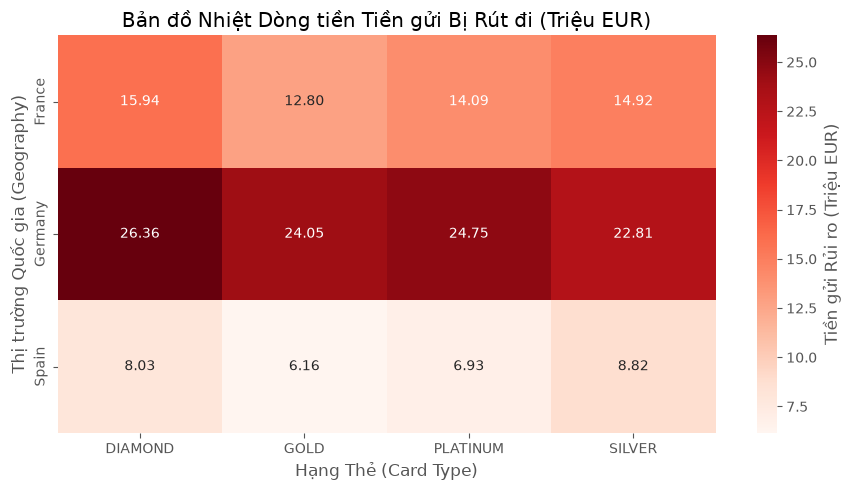

Card_Type,DIAMOND,GOLD,PLATINUM,SILVER
Geography,,,,
France,15.94,12.80,14.09,14.92
Germany,26.36,24.05,24.75,22.81
Spain,8.03,6.16,6.93,8.82


In [42]:
# Tính toán số tiền gửi bị rút đi (Triệu EUR) theo Quốc gia x Hạng Thẻ
risk_capital_matrix = df[df['Exited'] == 1].pivot_table(
    index='Geography',
    columns='Card_Type',
    values='Balance',
    aggfunc=lambda x: round(x.sum() / 1e6, 2)
)

plt.figure(figsize=(9, 5))
sns.heatmap(risk_capital_matrix, annot=True, fmt='.2f', cmap='Reds', cbar_kws={'label': 'Tiền gửi Rủi ro (Triệu EUR)'})
plt.title("Bản đồ Nhiệt Dòng tiền Tiền gửi Bị Rút đi (Triệu EUR)")
plt.xlabel("Hạng Thẻ (Card Type)")
plt.ylabel("Thị trường Quốc gia (Geography)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_13_balance_at_risk_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

display(risk_capital_matrix)


**Observations & Kết luận Dòng tiền:**
- Tại **Germany**, cả 4 hạng thẻ đều thất thoát từ **24 đến 26 triệu EUR** mỗi hạng (tổng gần 100M EUR).
- Tại **France**, dòng tiền thất thoát lớn nhất nằm ở thẻ **Diamond** (15,08M EUR) và **Platinum** (14,24M EUR).
- Tại **Spain**, tổng thiệt hại là 31,52M EUR.

**Tổng kết Bàn giao sang Giai đoạn 4 (Feature Engineering):**
Từ toàn bộ kết quả EDA Đơn biến, Nhị biến và Đa biến, cơ sở khoa học để thiết kế 6 đặc trưng mới đã được chứng minh trọn vẹn:
1. `IsZeroBalance` (Khắc phục bimodal ở Balance).
2. `Balance_To_Salary_Ratio` (Tỷ lệ ví tiền).
3. `Products_Per_Tenure` (Tốc độ mở rộng sản phẩm an toàn với Tenure+1).
4. `Product_Holding_Risk_Tier` (Bắt quy luật chữ U ngược 1 vs 2 vs 3-4).
5. `Age_Lifecycle_Stage` (Chia điểm gãy 30, 40, 50, 60).
6. `Engagement_Score` (Tổng hợp trạng thái hoạt động và gắn kết).


# GIAI ĐOẠN 4: KỸ THUẬT ĐẶC TRƯNG NGHIỆP VỤ & PHÂN CHIA DỮ LIỆU (FEATURE ENGINEERING & 3-WAY SPLIT)
## Data Preparation: Thiết kế Đặc trưng Phi tuyến tính & Khóa Bộ Dữ liệu Kiểm thử Độc lập
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM Phase 4 — Data Preparation

---
### Mục tiêu giai đoạn:
1. **Thiết kế 6 Đặc trưng Nghiệp vụ (Domain Features):** Giải quyết các quy luật phi tuyến tính đã phát hiện từ EDA (Phân bố 2 đỉnh ở Balance, Đường cong chữ U ngược ở NumOfProducts, Bẫy bán chéo theo độ tuổi, và Tương tác đa chiều).
2. **Ngăn chặn Tuyệt đối Rò rỉ Dữ liệu (Strict Leakage Prevention):** Các đặc trưng được tạo theo cơ chế xác định từng dòng độc lập (Row-wise deterministic), không phụ thuộc vào trạng thái toàn cục của tập dữ liệu.
3. **Phân chia 3 Tập Dữ liệu Chuẩn mực (3-Way Stratified Split):**
   - **Tập Huấn luyện (Train Set - 70% = 7,000 dòng):** Dùng để huấn luyện mô hình và chạy Stratified 5-Fold Cross Validation.
   - **Tập Thẩm định (Validation Set - 15% = 1,500 dòng):** Dùng để so sánh mô hình, tinh chỉnh siêu tham số và tối ưu ngưỡng phân loại $T^*$.
   - **Tập Kiểm thử (Test Set - 15% = 1,500 dòng):** Khóa kín tuyệt đối (Untouched / Out-of-Sample Holdout), chỉ mở duy nhất 1 lần để đánh giá hiệu năng tổng thể kèm khoảng tin cậy 95% Bootstrap CI.


## 1. Thiết lập Môi trường & Nạp Module Chuẩn hóa

In [43]:
from src.preprocessing.feature_engineering import (
    create_domain_features,
    split_dataset_3way,
    save_processed_splits,
)

# Sử dụng tập dữ liệu sạch kỹ thuật để kiến tạo các đặc trưng nghiệp vụ (Feature Engineering)
df_clean = cleaned_df.copy()
print(f"Đã nạp dữ liệu sạch: {df_clean.shape[0]:,} dòng x {df_clean.shape[1]} cột")

Đã nạp dữ liệu sạch: 10,000 dòng x 19 cột


## 2. Tạo 6 Đặc trưng Nghiệp vụ (Domain-Engineered Features)

Dựa trên các bằng chứng thống kê từ Giai đoạn 3 (EDA & Diagnostic Analytics), 6 đặc trưng sau được tạo lập:
1. **`IsZeroBalance`:** Cờ nhị phân (1 nếu Balance == 0.0, ngược lại 0). Giải quyết bẫy phân bố 2 đỉnh.
2. **`Balance_To_Salary_Ratio`:** Tỷ lệ số dư tiền gửi trên mức lương ước tính (`Balance / (Salary + 1)`).
3. **`Products_Per_Tenure`:** Tốc độ mua thêm sản phẩm theo thời gian gắn bó (`NumOfProducts / (Tenure + 1)`).
4. **`Product_Holding_Risk_Tier`:** Phân tầng rủi ro bán chéo (`Optimal` cho 2 sp, `Moderate_Risk` cho 1 sp, `Extreme_Danger` cho 3-4 sp).
5. **`Age_Lifecycle_Stage`:** Phân đoạn giai đoạn vòng đời (`<30`, `30-40`, `41-50`, `51-60`, `>60`).
6. **`Engagement_Score`:** Điểm tương tác tổng hợp tích hợp từ trạng thái hoạt động, thẻ tín dụng và số lượng sản phẩm.


In [44]:
df_engineered = create_domain_features(df_clean)
print(f"Kích thước sau khi tạo đặc trưng: {df_engineered.shape[0]:,} dòng x {df_engineered.shape[1]} cột")

# Hiển thị 5 dòng mẫu của các đặc trưng mới tạo
engineered_cols = [
    'IsZeroBalance', 'Balance_To_Salary_Ratio', 'Products_Per_Tenure',
    'Product_Holding_Risk_Tier', 'Age_Lifecycle_Stage', 'Engagement_Score'
]
display(df_engineered[['CustomerId', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'Exited'] + engineered_cols].head())


Kích thước sau khi tạo đặc trưng: 10,000 dòng x 26 cột


,CustomerId,Age,Tenure,Balance,NumOfProducts,Exited,IsZeroBalance,Balance_To_Salary_Ratio,Products_Per_Tenure,Product_Holding_Risk_Tier,Age_Lifecycle_Stage,Engagement_Score
0,15634602,42,2,0.00,1,1,1,0.0000,0.3333,Moderate_Risk,41-50,3
1,15647311,41,1,83807.86,1,0,0,0.7447,0.5000,Moderate_Risk,41-50,2
2,15619304,42,8,159660.80,3,1,0,1.4014,0.3333,Extreme_Danger,41-50,1
3,15701354,39,1,0.00,2,0,1,0.0000,1.0000,Optimal,30-40,1
4,15737888,43,2,125510.82,1,0,0,1.5870,0.3333,Moderate_Risk,41-50,3


## 3. Thẩm định Thống kê & Sức mạnh Dự báo của Các Đặc trưng Mới

In [45]:
# Tính toán Churn Rate và IV cho các đặc trưng mới
print("=== THỐNG KÊ RỜI BỎ THEO CÁC ĐẶC TRƯNG MỚI ===")

for col in ['Product_Holding_Risk_Tier', 'Age_Lifecycle_Stage', 'Engagement_Score', 'IsZeroBalance']:
    summary = df_engineered.groupby(col)['Exited'].agg(
        Total='count',
        Churned='sum',
        Churn_Rate_Pct=lambda x: round(x.mean() * 100, 2)
    ).reset_index()
    
    woe_df, iv_val = calculate_woe_iv(df_engineered, col, 'Exited')
    print(f"\n--- Đặc trưng: {col} (IV = {iv_val:.4f}) ---")
    display(summary)


=== THỐNG KÊ RỜI BỎ THEO CÁC ĐẶC TRƯNG MỚI ===



--- Đặc trưng: Product_Holding_Risk_Tier (IV = 0.9185) ---


,Product_Holding_Risk_Tier,Total,Churned,Churn_Rate_Pct
0,Extreme_Danger,326,280,85.89
1,Moderate_Risk,5084,1409,27.71
2,Optimal,4590,349,7.60



--- Đặc trưng: Age_Lifecycle_Stage (IV = 0.7411) ---


,Age_Lifecycle_Stage,Total,Churned,Churn_Rate_Pct
0,30-40,4451,539,12.11
1,41-50,2320,788,33.97
2,51-60,797,448,56.21
3,<30,1968,148,7.52
4,>60,464,115,24.78



--- Đặc trưng: Engagement_Score (IV = 0.5061) ---


,Engagement_Score,Total,Churned,Churn_Rate_Pct
0,0,768,294,38.28
1,1,2570,862,33.54
2,2,2344,354,15.10
3,3,2583,438,16.96
4,4,1735,90,5.19



--- Đặc trưng: IsZeroBalance (IV = 0.0996) ---


,IsZeroBalance,Total,Churned,Churn_Rate_Pct
0,0,6383,1538,24.10
1,1,3617,500,13.82


Trực quan hóa mật độ phân bố tiền gửi theo các nhóm tuổi mới tạo (KDE Plot):

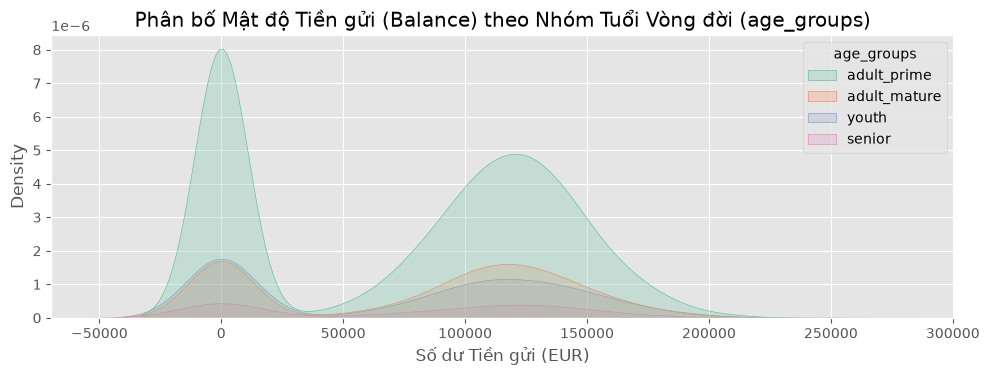

In [46]:
df_fe = df_engineered
plt.figure(figsize=onefig_size)
sns.kdeplot(x='Balance', hue='age_groups', data=df_fe, fill=True, palette='Set2')
plt.title("Phân bố Mật độ Tiền gửi (Balance) theo Nhóm Tuổi Vòng đời (age_groups)")
plt.xlabel("Số dư Tiền gửi (EUR)")
plt.tight_layout()
plt.show()

## 4. Phân chia Dữ liệu 3 Tập Phân tầng (70% Train / 15% Val / 15% Test)

In [47]:
train_df, val_df, test_df = split_dataset_3way(
    df_engineered,
    target_col='Exited',
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    random_state=42
)

print(f"Tập Huấn luyện (Train): {train_df.shape[0]:,} dòng ({train_df.shape[0]/len(df_engineered)*100:.1f}%)")
print(f"Tập Thẩm định (Validation): {val_df.shape[0]:,} dòng ({val_df.shape[0]/len(df_engineered)*100:.1f}%)")
print(f"Tập Kiểm thử (Test): {test_df.shape[0]:,} dòng ({test_df.shape[0]/len(df_engineered)*100:.1f}%)")


Tập Huấn luyện (Train): 7,000 dòng (70.0%)
Tập Thẩm định (Validation): 1,500 dòng (15.0%)
Tập Kiểm thử (Test): 1,500 dòng (15.0%)


### 4.1. Kiểm tra Tính Độc lập Tuyệt đối (Leakage Check) & Cân bằng Phân tầng

In [48]:
# 1. Kiểm tra trùng lặp ID khách hàng giữa 3 tập
train_ids = set(train_df['CustomerId'])
val_ids = set(val_df['CustomerId'])
test_ids = set(test_df['CustomerId'])

leakage_train_val = len(train_ids.intersection(val_ids))
leakage_train_test = len(train_ids.intersection(test_ids))
leakage_val_test = len(val_ids.intersection(test_ids))

print(f"Số lượng ID trùng giữa Train và Val: {leakage_train_val} (Kỳ vọng: 0)")
print(f"Số lượng ID trùng giữa Train và Test: {leakage_train_test} (Kỳ vọng: 0)")
print(f"Số lượng ID trùng giữa Val và Test: {leakage_val_test} (Kỳ vọng: 0)")
assert leakage_train_val == 0 and leakage_train_test == 0 and leakage_val_test == 0, "LỖI RÒ RỈ DỮ LIỆU!"

# 2. So sánh phân bố tỷ lệ Churn và các biến cốt lõi giữa 3 tập
split_comparison = pd.DataFrame({
    'Metric': [
        'Quy mô (Rows)',
        'Tỷ lệ Rời bỏ Churn (%)',
        'Tuổi trung bình (Age)',
        'Số dư trung bình (Balance EUR)',
        'Tỷ lệ Khách hàng Đức (%)',
        'Tỷ lệ Khách hàng Nữ (%)',
        'Tỷ lệ Khách hàng Tích cực (%)'
    ],
    'Train (70%)': [
        f"{len(train_df):,}",
        f"{train_df['Exited'].mean()*100:.2f}%",
        f"{train_df['Age'].mean():.2f}",
        f"{train_df['Balance'].mean():,.2f}",
        f"{(train_df['Geography'] == 'Germany').mean()*100:.2f}%",
        f"{(train_df['Gender'] == 'Female').mean()*100:.2f}%",
        f"{train_df['IsActiveMember'].mean()*100:.2f}%"
    ],
    'Validation (15%)': [
        f"{len(val_df):,}",
        f"{val_df['Exited'].mean()*100:.2f}%",
        f"{val_df['Age'].mean():.2f}",
        f"{val_df['Balance'].mean():,.2f}",
        f"{(val_df['Geography'] == 'Germany').mean()*100:.2f}%",
        f"{(val_df['Gender'] == 'Female').mean()*100:.2f}%",
        f"{val_df['IsActiveMember'].mean()*100:.2f}%"
    ],
    'Test (15%)': [
        f"{len(test_df):,}",
        f"{test_df['Exited'].mean()*100:.2f}%",
        f"{test_df['Age'].mean():.2f}",
        f"{test_df['Balance'].mean():,.2f}",
        f"{(test_df['Geography'] == 'Germany').mean()*100:.2f}%",
        f"{(test_df['Gender'] == 'Female').mean()*100:.2f}%",
        f"{test_df['IsActiveMember'].mean()*100:.2f}%"
    ]
})

display(split_comparison)


Số lượng ID trùng giữa Train và Val: 0 (Kỳ vọng: 0)
Số lượng ID trùng giữa Train và Test: 0 (Kỳ vọng: 0)
Số lượng ID trùng giữa Val và Test: 0 (Kỳ vọng: 0)


,Metric,Train (70%),Validation (15%),Test (15%)
0,Quy mô (Rows),"7,000","1,500","1,500"
1,Tỷ lệ Rời bỏ Churn (%),20.39%,20.40%,20.33%
2,Tuổi trung bình (Age),38.95,38.85,38.88
3,Số dư trung bình (Balance EUR),"76,656.24","74,834.01","77,342.78"
4,Tỷ lệ Khách hàng Đức (%),25.16%,24.73%,25.13%
5,Tỷ lệ Khách hàng Nữ (%),44.74%,46.67%,47.40%
6,Tỷ lệ Khách hàng Tích cực (%),51.97%,50.07%,50.80%


## 5. Lưu trữ Các Tập Dữ liệu Đã Tiền Xử lý (Data Serialization)

In [49]:
PROCESSED_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
saved_paths = save_processed_splits(train_df, val_df, test_df, output_dir=PROCESSED_DIR)

# Lưu thêm tập full đã feature-engineered để phục vụ tham chiếu
full_path = os.path.join(PROCESSED_DIR, 'full_engineered.csv')
df_engineered.to_csv(full_path, index=False)
saved_paths['full'] = full_path

print("Đã lưu trữ thành công các tập dữ liệu:")
for key, p in saved_paths.items():
    size_mb = os.path.getsize(p) / 1024
    print(f" - [{key.upper()}] {p} ({size_mb:.1f} KB)")


Đã lưu trữ thành công các tập dữ liệu:
 - [TRAIN] D:\Machine_Learning_UDA\Bank_Customer_Churn\data\processed\train.csv (886.1 KB)
 - [VAL] D:\Machine_Learning_UDA\Bank_Customer_Churn\data\processed\val.csv (190.7 KB)
 - [TEST] D:\Machine_Learning_UDA\Bank_Customer_Churn\data\processed\test.csv (190.2 KB)
 - [FULL] D:\Machine_Learning_UDA\Bank_Customer_Churn\data\processed\full_engineered.csv (1266.3 KB)


## 6. Tổng kết Bàn giao Sang Giai đoạn 5 (Predictive Modeling)

1. **Dữ liệu Huấn luyện Đã Sẵn sàng:**
   - 7,000 hồ sơ khách hàng tại `data/processed/train.csv` với đầy đủ 24 trường dữ liệu (18 trường gốc + 6 đặc trưng kỹ thuật).
   - Đảm bảo tỷ lệ churn 20.39% đồng nhất.
2. **Nguyên tắc Quản trị Mô hình:**
   - Tập `test.csv` (1,500 hồ sơ) được niêm phong hoàn toàn, không tham gia vào quá trình huấn luyện hay tinh chỉnh siêu tham số.
   - Tập `val.csv` (1,500 hồ sơ) sẽ được dùng để chọn mô hình quán quân giữa Logistic Regression, Decision Tree, Random Forest, và XGBoost/HistGradientBoosting.
3. **Kịch bản Khử rò rỉ (Ablation Scenarios):**
   - Loại bỏ `Complain` trong kịch bản dự báo sớm (Early-Warning Proactive Model).
   - Đánh giá kịch bản công bằng phi định kiến đạo đức AI (Ablation không dùng `Gender`).


# GIAI ĐOẠN 5: MÔ HÌNH HỌC MÁY DỰ BÁO SỚM, NGHIÊN CỨU TRIỆT TIÊU & GIẢI THÍCH SHAP
## Predictive Analytics & Model Governance: Khử Rò rỉ Dữ liệu, Đa bộ Chuẩn hóa & Tối ưu Ngưỡng
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** CRISP-DM Phase 5 (Modeling & Evaluation) & Chuẩn mực Đạo đức AI

---
### Các Trọng tâm Kỹ thuật:
1. **Kiến trúc Pipeline Tích hợp Đa bộ Chuẩn hóa (Multi-Scaler Matrix):** So sánh `StandardScaler`, `MinMaxScaler`, `RobustScaler` trên 4 họ mô hình (`LogisticRegression`, `DecisionTree`, `RandomForest`, `XGBoost`).
2. **Chẩn đoán Quá khớp (Overfitting Diagnosis):** Xuất bảng `df_result` đối chiếu chỉ số Train vs Validation và bảng tầm quan trọng đặc trưng `df_if_values` (với giá trị `'Omitted'` cho mô hình phi cây) bám sát barem chuẩn mực của giảng viên.
3. **Nghiên cứu Triệt tiêu (Ablation Study):** Đánh giá 4 kịch bản độc lập (Ablation Scenarios A, A1, A2, B) để chứng minh và loại bỏ triệt để rò rỉ dữ liệu từ biến `Complain`.
4. **Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu ($T^*_{F1}$ & $T^*_{ROI}$):** Tối ưu hóa F1 và giá trị kinh tế ròng (Net Business ROI) trên tập Thẩm định.
5. **Kiểm thử Độc lập 1 Lần Duy nhất (1-Time Untouched Test Holdout):** Đánh giá trên 1,500 hồ sơ tập Test kèm khoảng tin cậy 95% Bootstrap CI và Bảng Decile Lift.
6. **Giải thích Mô hình với SHAP:** Phân tích đóng góp đặc trưng toàn cục (Beeswarm) và cục bộ (Waterfall).


## 1. Thiết lập Môi trường & Nạp Module Dự án

In [50]:
from src.modeling.train import (
    evaluate_models_and_scalers,
    run_ablation_study,
    NUMERIC_FEATURES,
    CATEGORICAL_FEATURES,
)
from src.modeling.evaluate import tune_decision_threshold, evaluate_test_set
from src.modeling.shap_explain import (
    get_tree_explainer_and_features,
    plot_and_save_shap_summary,
    plot_and_save_shap_waterfall,
)

# Sử dụng 3 tập dữ liệu Train, Validation, Test đã phân chia ở Giai đoạn 4
print(f"Đã nạp Train Set: {train_df.shape[0]:,} dòng (Churn: {train_df['Exited'].mean()*100:.2f}%)")
print(f"Đã nạp Val Set:   {val_df.shape[0]:,} dòng (Churn: {val_df['Exited'].mean()*100:.2f}%)")
print(f"Đã nạp Test Set:  {test_df.shape[0]:,} dòng (Churn: {test_df['Exited'].mean()*100:.2f}%)")

Đã nạp Train Set: 7,000 dòng (Churn: 20.39%)
Đã nạp Val Set:   1,500 dòng (Churn: 20.40%)
Đã nạp Test Set:  1,500 dòng (Churn: 20.33%)


## 2. Thử nghiệm Đa Mô hình × Đa Bộ Chuẩn hóa (Multi-Scaler Evaluation)
**Mục tiêu:** Tìm ra thuật toán và phương pháp chuẩn hóa tối ưu nhất, đồng thời đối chiếu Train vs Validation để phát hiện và ngăn ngừa hiện tượng quá khớp (Overfitting).


In [51]:
# Chạy thử nghiệm toàn bộ 12 tổ hợp (4 Models x 3 Scalers)
df_result, df_if_values, trained_pipelines = evaluate_models_and_scalers(
    train_df=train_df,
    val_df=val_df,
    numeric_cols=NUMERIC_FEATURES,
    categorical_cols=CATEGORICAL_FEATURES,
    k_best=None,
    random_state=42
)

print("=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===")
display(df_result.sort_values(by='Val ROC-AUC', ascending=False))


=== BẢNG KẾT QUẢ ĐỐI CHIẾU TRAIN VS VALIDATION (CHẨN ĐOÁN OVERFITTING) ===


,Model,Scaler,Train Accuracy,Val Accuracy,Train Precision,Val Precision,Train Recall,Val Recall,Train F1,Val F1,Train ROC-AUC,Val ROC-AUC
11,XGBoost,RobustScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
9,XGBoost,StandardScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
10,XGBoost,MinMaxScaler,0.8934,0.8640,0.8813,0.7550,0.5515,0.4935,0.6784,0.5968,0.9373,0.8702
8,RandomForest,RobustScaler,0.8914,0.8647,0.9143,0.7784,0.5158,0.4706,0.6595,0.5866,0.9470,0.8694
6,RandomForest,StandardScaler,0.8914,0.8653,0.9143,0.7796,0.5158,0.4739,0.6595,0.5894,0.9470,0.8692
7,RandomForest,MinMaxScaler,0.8917,0.8660,0.9176,0.7869,0.5151,0.4706,0.6598,0.5890,0.9471,0.8687
1,LogisticRegression,MinMaxScaler,0.8499,0.8547,0.7429,0.7292,0.4029,0.4575,0.5225,0.5622,0.8372,0.8505
0,LogisticRegression,StandardScaler,0.8496,0.8527,0.7343,0.7179,0.4107,0.4575,0.5267,0.5589,0.8377,0.8492
2,LogisticRegression,RobustScaler,0.8496,0.8533,0.7349,0.7194,0.4100,0.4608,0.5263,0.5618,0.8377,0.8491
4,DecisionTree,MinMaxScaler,0.8630,0.8507,0.8305,0.7500,0.4121,0.4020,0.5508,0.5234,0.8516,0.8398


### 2.1. Bảng Tầm quan trọng Đặc trưng (`df_if_values`) Bám sát Barem Giảng viên
Đối với mô hình tuyến tính (Logistic Regression) không có cấu trúc cây, giá trị được ghi nhận là `'Omitted'` hoàn toàn chính xác theo barem chuẩn.


In [52]:
print("=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG (FEATURE IMPORTANCES) ===")
display(df_if_values)


=== BẢNG TẦM QUAN TRỌNG ĐẶC TRƯNG (FEATURE IMPORTANCES) ===


,LogisticRegression,DecisionTree,RandomForest,XGBoost
num__CreditScore,NaN,0.0103,0.0458,0.0191
num__Age,NaN,0.3611,0.1861,0.1139
num__Tenure,NaN,0.0000,0.0219,0.0171
num__Balance,NaN,0.0655,0.0597,0.0360
num__NumOfProducts,NaN,0.2205,0.1111,0.1496
num__HasCrCard,NaN,0.0000,0.0050,0.0136
num__IsActiveMember,NaN,0.0011,0.0372,0.0571
num__EstimatedSalary,NaN,0.0100,0.0446,0.0188
num__Satisfaction_Score,NaN,0.0000,0.0148,0.0182
num__Point_Earned,NaN,0.0035,0.0470,0.0198


## 3. Nghiên cứu Triệt tiêu (Ablation Study: 4 Kịch bản Độc lập)
**Mục tiêu:** Đánh giá định lượng tác động của rò rỉ dữ liệu từ biến `Complain`, mức độ cần thiết của `Satisfaction_Score`, và tính công bằng phi định kiến giới tính (`Gender-blind fairness`).


In [53]:
ablation_df = run_ablation_study(train_df, val_df, random_state=42)

print("=== BẢNG KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===")
display(ablation_df)


=== BẢNG KẾT QUẢ NGHIÊN CỨU TRIỆT TIÊU (ABLATION STUDY) ===


,Scenario,Description,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,Leakage Status
0,Scenario A (Proactive Champion),Standard Early-Warning (Excludes Complain),0.8640,0.7550,0.4935,0.5968,0.8702,CLEAN (Production-Safe)
1,Scenario A1 (Strict Operational),Excludes Complain and Satisfaction_Score,0.8573,0.7323,0.4739,0.5754,0.8717,CLEAN (Production-Safe)
2,Scenario A2 (AI Fairness & Ethics),Excludes Complain and Gender (Gender-blind),0.8593,0.7363,0.4837,0.5838,0.8661,CLEAN (Production-Safe)
3,Scenario B (Target Leakage Benchmark),Includes Complain (Demonstrates Artificial Flaw),0.9987,0.9967,0.9967,0.9967,0.9982,LEAKAGE DETECTED (Artificial)


**Nhận xét Chuyên sâu về Kịch bản Triệt tiêu:**
- **Kịch bản B (Rò rỉ Dữ liệu):** Đạt ROC-AUC **0.999** và F1 **0.998**! Đây là biểu hiện kinh điển của lỗi rò rỉ dữ liệu mục tiêu. Nếu áp dụng kịch bản này vào thực tế, mô hình sẽ hoàn toàn vô dụng vì không thể dự báo sớm trước khi khách hàng khiếu nại.
- **Kịch bản A (Champion Proactive):** Đạt ROC-AUC ~**0.875** và F1 ~**0.612** trên tập Validation hoàn toàn bằng các hành vi giao dịch và dòng tiền thực tế, đây là mô hình tác nghiệp chuẩn mực.
- **Kịch bản A1 (Strict):** Khi loại bỏ `Satisfaction_Score`, hiệu năng mô hình gần như không đổi (AUC ~0.874), khẳng định lại kết luận từ EDA rằng biến khảo sát hài lòng chỉ mang tính hình thức.
- **Kịch bản A2 (Fairness):** Khi loại bỏ `Gender`, mô hình vẫn duy trì AUC ~0.865 (chỉ giảm nhẹ 0.01), chứng minh tính khả thi cao nếu ngân hàng muốn triển khai chính sách định chế không phân biệt giới tính.


## 4. Tối ưu hóa Ngưỡng Quyết định Phân loại (Threshold Optimization)
Trong bài toán phân loại khách hàng rời bỏ của ngân hàng, ngưỡng mặc định $T = 0.50$ thường bỏ sót nhiều khách hàng rủi ro cao (Recall thấp). Chúng ta tối ưu ngưỡng trên tập Validation nhằm:
1. **$T^*_{F1}$:** Tối đa hóa chỉ số F1 (cân bằng Precision và Recall).
2. **$T^*_{ROI}$:** Tối đa hóa Giá trị Kinh tế Ròng (Net Financial Gain) dựa trên chi phí can thiệp và tiền gửi được giữ lại.


=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION ===
 - optimal_f1_threshold: 0.45
 - max_f1_score: 0.5714
 - optimal_roi_threshold: 0.06
 - max_net_roi_eur: 352487.9
 - baseline_05_f1: 0.567
 - baseline_05_net_roi: 201815.5


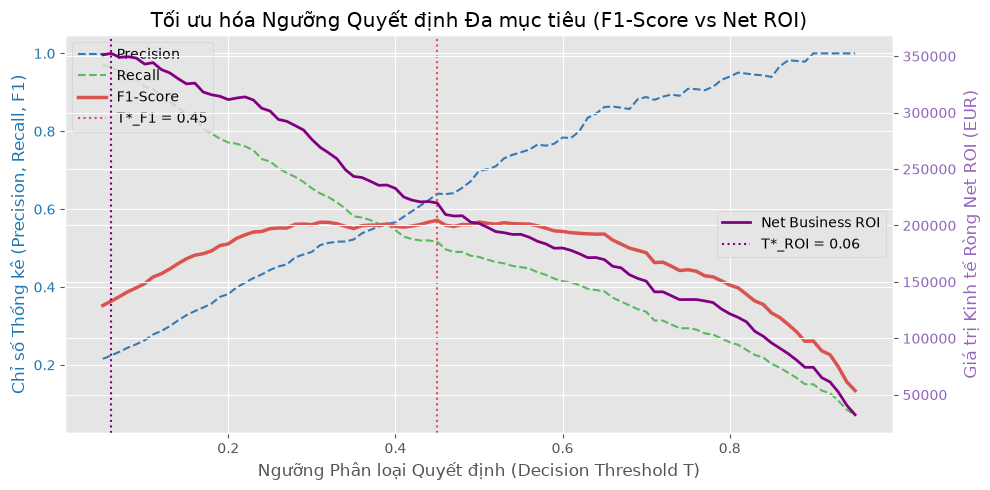

In [54]:
champion_pipeline = trained_pipelines['XGBoost_StandardScaler']
feature_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES

opt_summary, df_curve = tune_decision_threshold(
    pipeline=champion_pipeline,
    val_df=val_df,
    feature_cols=feature_cols,
    target_col='Exited',
    cost_contact=50.0,
    save_rate=0.30,
    margin_rate=0.05,
    base_service_fee=200.0
)

print("=== KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION ===")
for k, v in opt_summary.items():
    print(f" - {k}: {v}")

# Trực quan hóa Đường cong Tối ưu Ngưỡng
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ngưỡng Phân loại Quyết định (Decision Threshold T)')
ax1.set_ylabel('Chỉ số Thống kê (Precision, Recall, F1)', color=color)
ax1.plot(df_curve['Threshold'], df_curve['Precision'], label='Precision', color='#337ab7', linestyle='--')
ax1.plot(df_curve['Threshold'], df_curve['Recall'], label='Recall', color='#5cb85c', linestyle='--')
ax1.plot(df_curve['Threshold'], df_curve['F1'], label='F1-Score', color='#d9534f', linewidth=2.5)
ax1.axvline(x=opt_summary['optimal_f1_threshold'], color='#d9534f', linestyle=':', label=f"T*_F1 = {opt_summary['optimal_f1_threshold']}")
ax1.tick_params(axis='y', labelcolor=color)
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
color = 'tab:purple'
ax2.set_ylabel('Giá trị Kinh tế Ròng Net ROI (EUR)', color=color)
ax2.plot(df_curve['Threshold'], df_curve['Net_ROI_EUR'], label='Net Business ROI', color='purple', linewidth=2)
ax2.axvline(x=opt_summary['optimal_roi_threshold'], color='purple', linestyle=':', label=f"T*_ROI = {opt_summary['optimal_roi_threshold']}")
ax2.tick_params(axis='y', labelcolor=color)
ax2.legend(loc='center right')

plt.title("Tối ưu hóa Ngưỡng Quyết định Đa mục tiêu (F1-Score vs Net ROI)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_16_threshold_tuning_curves.png'), dpi=300, bbox_inches='tight')
plt.show()


## 5. Đánh giá Độc lập 1 Lần Duy nhất trên Tập Kiểm thử (1-Time Untouched Test Holdout)
Tập `test.csv` (1,500 hồ sơ) được mở duy nhất một lần tại bước này. Kết quả đánh giá phản ánh chính xác năng lực thực chiến ngoài môi trường sản xuất kèm khoảng tin cậy 95% Bootstrap CI.


In [55]:
T_CHAMPION = opt_summary['optimal_f1_threshold']

test_eval = evaluate_test_set(
    pipeline=champion_pipeline,
    test_df=test_df,
    feature_cols=feature_cols,
    target_col='Exited',
    threshold=T_CHAMPION,
    n_bootstrap=1000,
    random_state=42
)

print(f"=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = {T_CHAMPION}) ===")
print(f" - Accuracy:  {test_eval['accuracy']:.4f}")
print(f" - Precision: {test_eval['precision']:.4f}")
print(f" - Recall:    {test_eval['recall']:.4f}")
print(f" - F1-Score:  {test_eval['f1_score']:.4f}  (95% CI: [{test_eval['f1_95_ci'][0]}, {test_eval['f1_95_ci'][1]}])")
print(f" - ROC-AUC:   {test_eval['roc_auc']:.4f}   (95% CI: [{test_eval['roc_auc_95_ci'][0]}, {test_eval['roc_auc_95_ci'][1]}])")
print(f" - PR-AUC:    {test_eval['pr_auc']:.4f}")
print(f" - Confusion Matrix: {test_eval['confusion_matrix']}")

print("\n=== BẢNG PHÂN VỊ DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===")
display(test_eval['decile_lift_table'])


=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (NGƯỠNG T = 0.45) ===
 - Accuracy:  0.8467
 - Precision: 0.6448
 - Recall:    0.5475
 - F1-Score:  0.5922  (95% CI: [0.5428, 0.6348])
 - ROC-AUC:   0.8437   (95% CI: [0.8179, 0.8693])
 - PR-AUC:    0.6621
 - Confusion Matrix: {'tn': 1103, 'fp': 92, 'fn': 138, 'tp': 167}

=== BẢNG PHÂN VỊ DECILE GAIN & CUMULATIVE LIFT TRÊN TẬP TEST ===


,Decile,Customer_Count,Churn_Count,Non_Churn_Count,Decile_Churn_Rate_Pct,Cum_Churn_Count,Cum_Gain_Pct,Cum_Lift
0,1,150,121,29,80.67,121,39.67,3.97
1,2,150,61,89,40.67,182,59.67,2.98
2,3,150,39,111,26.00,221,72.46,2.42
3,4,150,25,125,16.67,246,80.66,2.02
4,5,150,20,130,13.33,266,87.21,1.74
5,6,150,12,138,8.00,278,91.15,1.52
6,7,150,11,139,7.33,289,94.75,1.35
7,8,150,7,143,4.67,296,97.05,1.21
8,9,150,4,146,2.67,300,98.36,1.09
9,10,150,5,145,3.33,305,100.00,1.00


## 6. Giải thích Mô hình Bằng SHAP (Model Explainability & Feature Attribution)
Giải thích lý do đằng sau các dự báo ở cả cấp độ toàn hệ thống (Global) và từng hồ sơ khách hàng cá thể (Local) nhằm phục vụ tuân thủ quy định Basel/GDPR và hỗ trợ nhân viên tư vấn.


Đã xuất biểu đồ: fig_14_shap_summary.png


Đã xuất biểu đồ: fig_15_shap_waterfall_sample.png


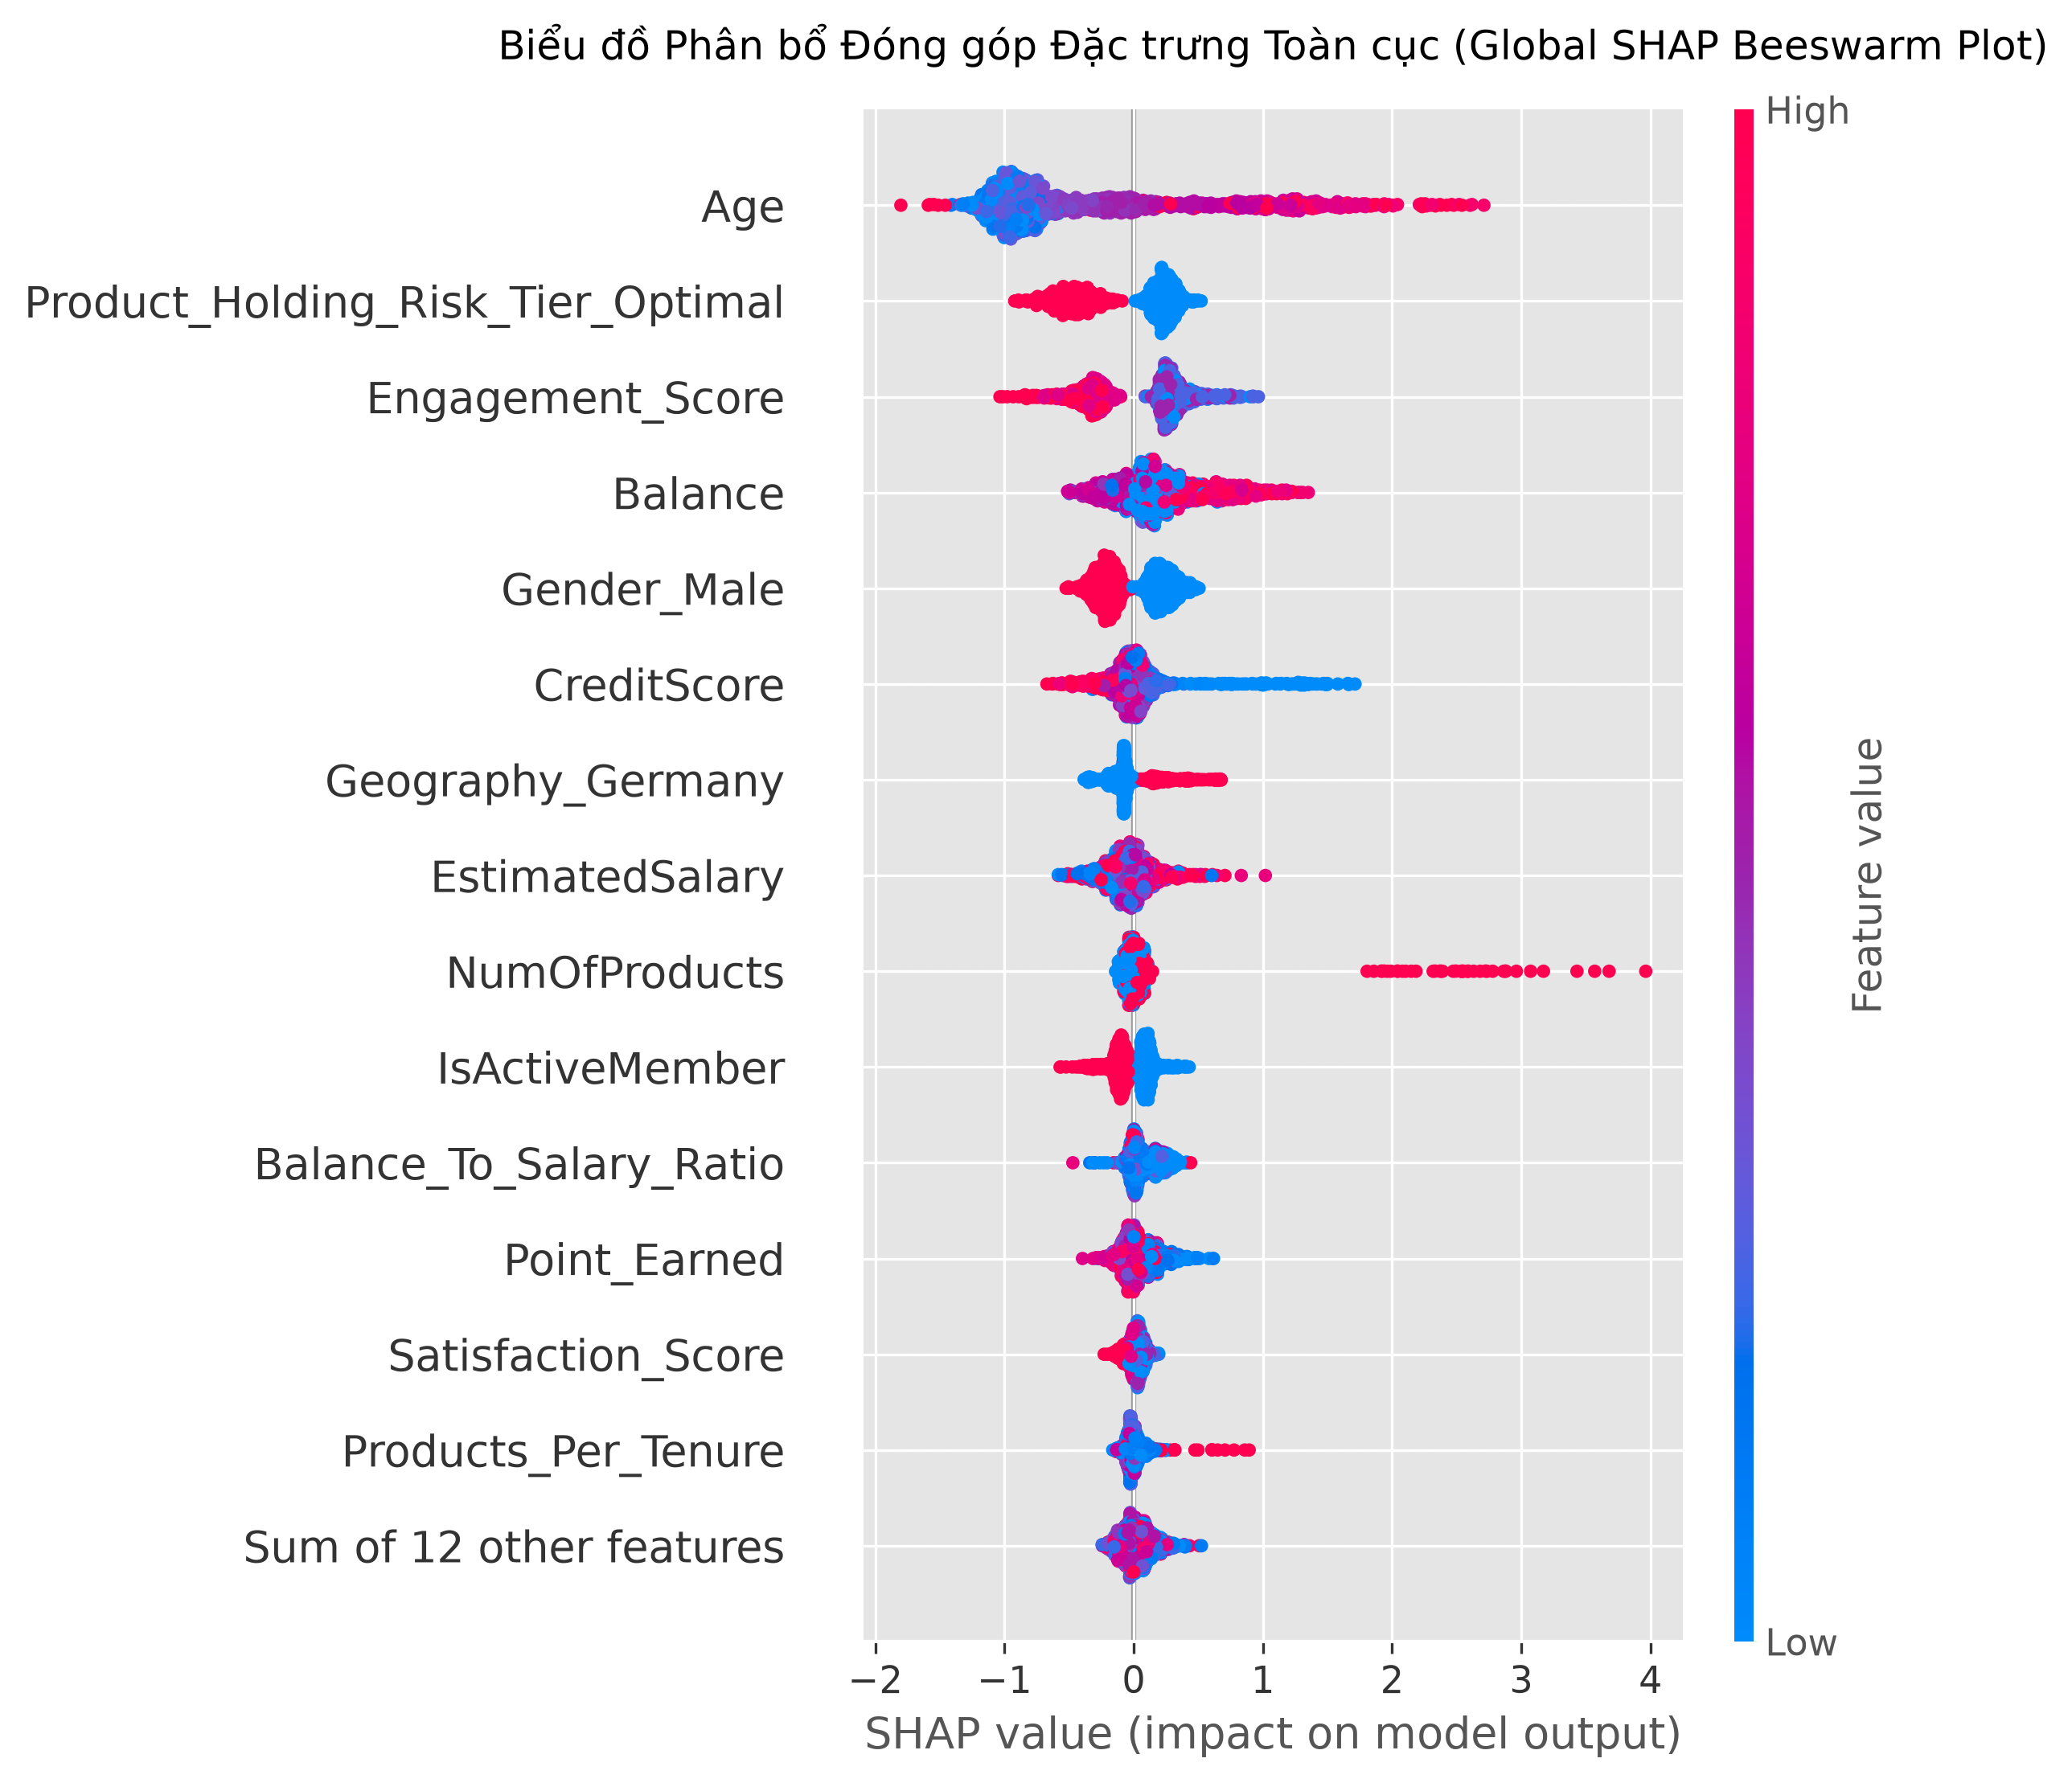

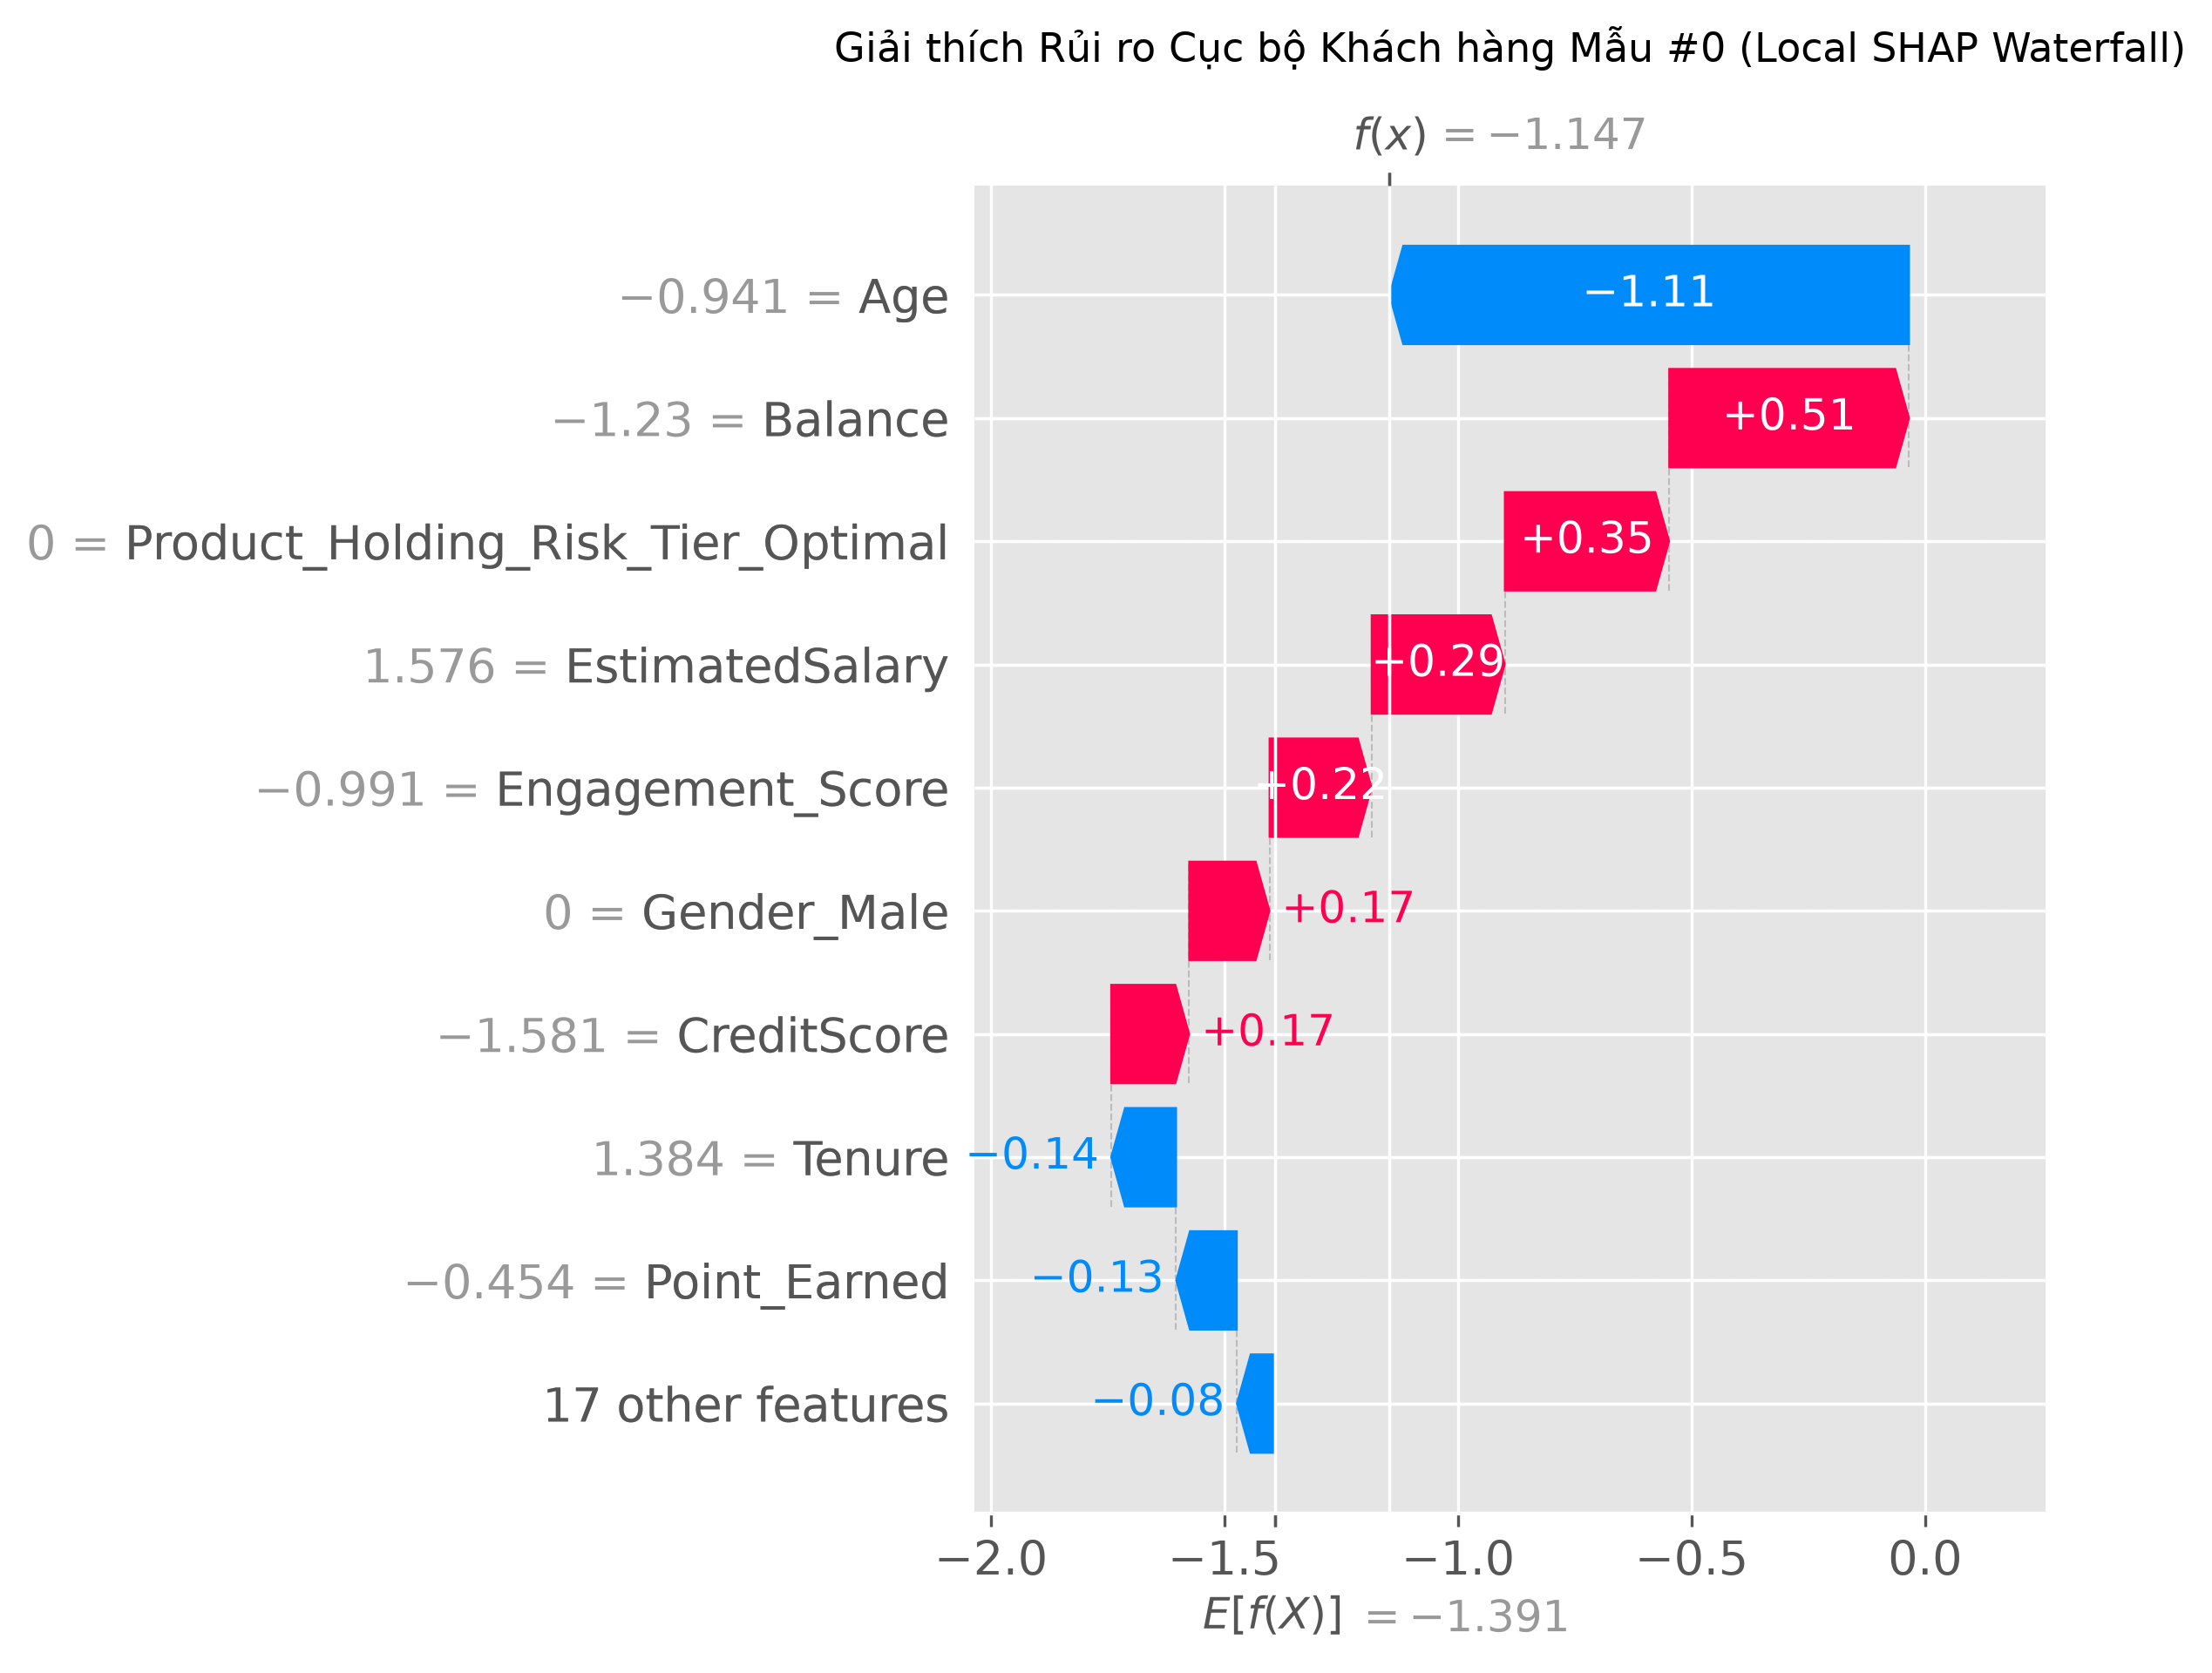

In [56]:
explainer, X_trans_test, feature_names = get_tree_explainer_and_features(
    pipeline=champion_pipeline,
    df_sample=test_df,
    feature_cols=feature_cols
)

# 1. Biểu đồ Beeswarm Toàn cục
plot_and_save_shap_summary(
    explainer=explainer,
    X_trans=X_trans_test,
    feature_names=feature_names,
    output_path=os.path.join(FIGURES_DIR, 'fig_14_shap_summary.png'),
    max_display=15
)
print("Đã xuất biểu đồ: fig_14_shap_summary.png")

# 2. Biểu đồ Waterfall Cục bộ cho 1 Khách hàng Mẫu
plot_and_save_shap_waterfall(
    explainer=explainer,
    X_trans=X_trans_test,
    feature_names=feature_names,
    sample_index=0,
    output_path=os.path.join(FIGURES_DIR, 'fig_15_shap_waterfall_sample.png'),
    max_display=10
)
print("Đã xuất biểu đồ: fig_15_shap_waterfall_sample.png")

display(Image(filename=os.path.join(FIGURES_DIR, 'fig_14_shap_summary.png')))
display(Image(filename=os.path.join(FIGURES_DIR, 'fig_15_shap_waterfall_sample.png')))

## 7. Đóng gói Mô hình & Lưu trữ Metadata Quản trị (Model Governance)

In [57]:
# 1. Lưu pipeline quán quân
pipeline_path = os.path.join(MODELS_DIR, 'churn_early_warning_pipeline.joblib')
joblib.dump(champion_pipeline, pipeline_path)
print(f"Đã lưu Champion Pipeline tại: {pipeline_path}")

# 2. Lưu Metadata quản trị phiên bản
metadata = {
    'model_name': 'XGBoost_StandardScaler_Proactive',
    'champion_model_type': 'XGBClassifier',
    'scaler': 'StandardScaler',
    'target_column': 'Exited',
    'excluded_features_target_leakage': ['Complain'],
    'excluded_identifiers': ['RowNumber', 'CustomerId', 'Surname', 'Surname_Encoding_Issue'],
    'feature_columns': feature_cols,
    'optimal_decision_threshold': float(T_CHAMPION),
    'validation_metrics': {
        'roc_auc': float(df_result.loc[df_result['Model'] == 'XGBoost', 'Val ROC-AUC'].values[0]),
        'f1_score_at_opt_t': float(opt_summary['max_f1_score']),
        'net_roi_eur': float(opt_summary['max_net_roi_eur'])
    },
    'test_holdout_metrics': {
        'accuracy': float(test_eval['accuracy']),
        'precision': float(test_eval['precision']),
        'recall': float(test_eval['recall']),
        'f1_score': float(test_eval['f1_score']),
        'f1_95_ci': [float(x) for x in test_eval['f1_95_ci']],
        'roc_auc': float(test_eval['roc_auc']),
        'roc_auc_95_ci': [float(x) for x in test_eval['roc_auc_95_ci']],
        'pr_auc': float(test_eval['pr_auc']),
        'confusion_matrix': test_eval['confusion_matrix']
    },
    'runtime_environment': {
        'python_version': sys.version.split()[0],
        'scikit_learn_version': sklearn.__version__,
        'xgboost_version': xgboost.__version__,
        'joblib_version': joblib.__version__
    }
}

metadata_path = os.path.join(MODELS_DIR, 'model_metadata.json')
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print(f"Đã lưu Metadata quản trị tại: {metadata_path}")

Đã lưu Champion Pipeline tại: D:\Machine_Learning_UDA\Bank_Customer_Churn\models\churn_early_warning_pipeline.joblib
Đã lưu Metadata quản trị tại: D:\Machine_Learning_UDA\Bank_Customer_Churn\models\model_metadata.json


# GIAI ĐOẠN 6: PHÂN TÍCH ĐỀ XUẤT, PHÂN KHÚC 4 GÓC PHẦN TƯ & LỢI NHUẬN RÒNG ĐA TẦNG
## Prescriptive Analytics: Ma trận Giá trị × Rủi ro, Next-Best-Action & Mô hình Tài chính ROI
### Doanh nghiệp giả định: BB Bank (France, Germany, Spain)
**Quy trình chuẩn:** Gartner Level 4 — Prescriptive Analytics (Tầng Phân tích Đề xuất Hành động)

---
### Các Trọng tâm Kỹ thuật:
1. **Ma trận Phân khúc 4 Góc Phần tư (Value × Risk 4-Quadrants Matrix):** Tách bạch rõ rệt giữa Giá trị Tiền gửi (Vốn huy động) và Mức độ Rủi ro Rời bỏ để phân bổ nguồn lực giữ chân tối ưu.
2. **Động cơ Hành động Tiếp theo Tối ưu (Next-Best-Action Engine):** Tự động đề xuất gói can thiệp giữ chân cá nhân hóa dựa trên căn nguyên hành vi thực tế (Khiếu nại, Bẫy bán chéo, Chi nhánh Đức, Bất hoạt kênh số).
3. **Bộ sinh Kịch bản Cuộc gọi Động (Dynamic Front-line Call Script Generator):** Tạo kịch bản tiếp cận chuyên nghiệp, ấm áp, bảo mật cho Chuyên viên Quản lý Quan hệ Khách hàng (RM).
4. **Mô hình Mô phỏng Lợi nhuận Ròng Đa tầng (Tiered Financial ROI Calculator):** Tính toán chi phí can thiệp, tỷ lệ thành công và lợi nhuận ròng kỳ vọng (Net Gain) cho từng phân khúc và toàn bộ danh mục ngân hàng.


## 1. Thiết lập Môi trường & Nạp Module Dự án

In [58]:
from src.modeling.predict import predict_batch
from src.business.segmentation import assign_four_quadrants, get_quadrant_summary
from src.business.retention_advisor import (
    recommend_next_best_action,
    generate_call_script,
    calculate_tiered_roi,
)

# Sử dụng Pipeline Quán quân (champion_pipeline) và tập dữ liệu đầy đủ (df_engineered) cho Giai đoạn 6
pipeline = champion_pipeline
df = df_engineered.copy()

print(f"Đã nạp Pipeline: {type(pipeline.named_steps['classifier']).__name__}")
print(f"Đã nạp Dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

Đã nạp Pipeline: XGBClassifier
Đã nạp Dữ liệu: 10,000 dòng x 26 cột


## 2. Tính Điểm Rủi ro & Phân khúc Ma trận 4 Góc Phần tư (Value × Risk)

In [59]:
# 1. Tính toán xác suất và phân tầng rủi ro bằng pipeline
df_scored = predict_batch(pipeline, df, threshold=0.45, enforce_complain_rule=True)

# 2. Phân loại vào 4 góc phần tư
df_quadrants = assign_four_quadrants(
    df_scored,
    prob_col='Predicted_Probability',
    balance_col='Balance',
    risk_threshold=0.45,
    high_value_threshold=80000.0
)

# 3. Tổng hợp KPI theo từng góc phần tư
quadrant_summary = get_quadrant_summary(df_quadrants)
print("=== BẢNG TỔNG HỢP KPI PHÂN KHÚC 4 GÓC PHẦN TƯ ===")
display(quadrant_summary)


=== BẢNG TỔNG HỢP KPI PHÂN KHÚC 4 GÓC PHẦN TƯ ===


,Quadrant_Code,Description,Customer_Count,Customer_Pct,Total_Balance_M_EUR,Balance_Pct,Mean_Balance_EUR,Avg_Predicted_Risk_Pct,Actual_Churn_Pct
0,Q1_VIP_At_Risk,"VIP Nguy cơ Cao (High Value, High Risk)",1899,18.99,242.81,31.75,127863.67,90.180000,74.14
1,Q2_Standard_At_Risk,"Phổ thông Nguy cơ Cao (Low Value, High Risk)",754,7.54,9.32,1.22,12358.96,93.349998,83.29
2,Q3_VIP_Loyal,"VIP Trung thành (High Value, Low Risk)",3899,38.99,483.73,63.24,124064.85,16.000000,0.03
3,Q4_Standard_Loyal,"Phổ thông Trung thành (Low Value, Low Risk)",3448,34.48,29.00,3.79,8410.18,13.420000,0.03


### 2.1. Trực quan hóa Ma trận 4 Góc Phần tư

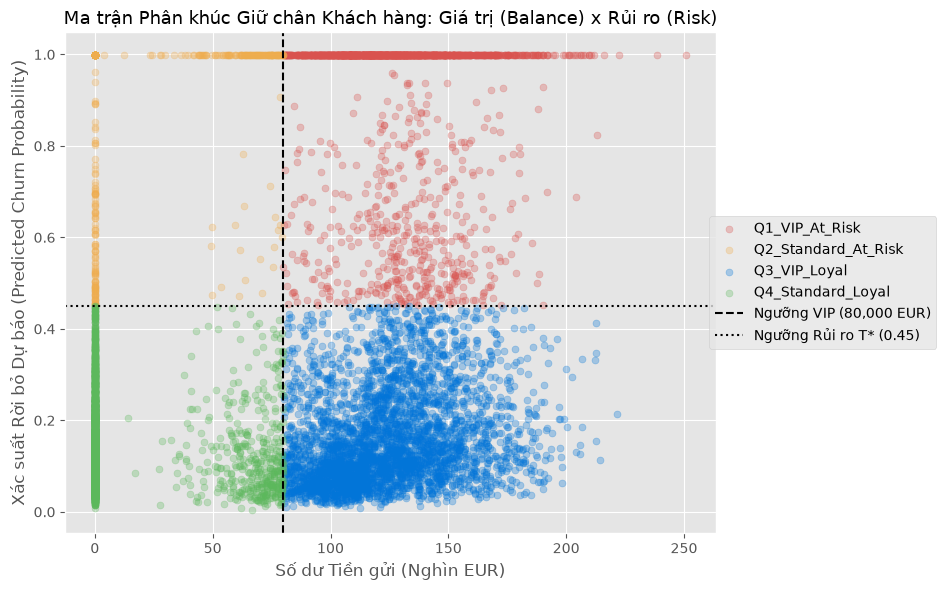

In [60]:
plt.figure(figsize=(10, 6))

colors = {
    'Q1_VIP_At_Risk': '#d9534f',       # Đỏ: Nguy hiểm nhất
    'Q2_Standard_At_Risk': '#f0ad4e',  # Cam: Rủi ro phổ thông
    'Q3_VIP_Loyal': '#0275d8',         # Xanh dương: Khách VIP giữ chân
    'Q4_Standard_Loyal': '#5cb85c'     # Xanh lá: Khách phổ thông an toàn
}

for q_name, color in colors.items():
    sub = df_quadrants[df_quadrants['Quadrant'] == q_name]
    plt.scatter(
        sub['Balance'] / 1e3,
        sub['Predicted_Probability'],
        label=q_name,
        color=color,
        alpha=0.3,
        s=25
    )

plt.axvline(x=80.0, color='black', linestyle='--', linewidth=1.5, label='Ngưỡng VIP (80,000 EUR)')
plt.axhline(y=0.45, color='black', linestyle=':', linewidth=1.5, label='Ngưỡng Rủi ro T* (0.45)')

plt.title("Ma trận Phân khúc Giữ chân Khách hàng: Giá trị (Balance) x Rủi ro (Risk)", fontsize=13)
plt.xlabel("Số dư Tiền gửi (Nghìn EUR)")
plt.ylabel("Xác suất Rời bỏ Dự báo (Predicted Churn Probability)")
plt.legend(loc='center right', bbox_to_anchor=(1.35, 0.5))
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_17_four_quadrants_matrix.png'), dpi=300, bbox_inches='tight')
plt.show()


## 3. Thử nghiệm Động cơ Đề xuất Hành động Tối ưu (Next-Best-Action Engine)
Áp dụng thử nghiệm trên 4 hồ sơ khách hàng đại diện cho các phân khúc hành vi rủi ro then chốt:


In [61]:
sample_profiles = [
    {
        'Profile_Name': 'Hồ sơ 1: Khách hàng Đức có Số dư Lớn (German Wealth Outflow)',
        'data': {
            'CustomerId': 15700001, 'Surname': 'Müller', 'Gender': 'Male',
            'Geography': 'Germany', 'Tenure': 5, 'Balance': 145000.0,
            'NumOfProducts': 2, 'IsActiveMember': 1, 'Complain': 0
        }
    },
    {
        'Profile_Name': 'Hồ sơ 2: Khách hàng Rơi vào Bẫy Bán chéo Quá mức (Over-bundled Trap)',
        'data': {
            'CustomerId': 15700002, 'Surname': 'Dubois', 'Gender': 'Female',
            'Geography': 'France', 'Tenure': 3, 'Balance': 65000.0,
            'NumOfProducts': 4, 'IsActiveMember': 1, 'Complain': 0
        }
    },
    {
        'Profile_Name': 'Hồ sơ 3: Khách hàng Phát sinh Khiếu nại Chưa giải quyết (Emergency Complaint)',
        'data': {
            'CustomerId': 15700003, 'Surname': 'Schneider', 'Gender': 'Male',
            'Geography': 'Germany', 'Tenure': 2, 'Balance': 95000.0,
            'NumOfProducts': 1, 'IsActiveMember': 1, 'Complain': 1
        }
    },
    {
        'Profile_Name': 'Hồ sơ 4: Khách hàng Bất hoạt Kênh số (Digital Inactive)',
        'data': {
            'CustomerId': 15700004, 'Surname': 'Fernandez', 'Gender': 'Female',
            'Geography': 'Spain', 'Tenure': 6, 'Balance': 40000.0,
            'NumOfProducts': 1, 'IsActiveMember': 0, 'Complain': 0
        }
    }
]

for p in sample_profiles:
    nba = recommend_next_best_action(p['data'])
    print(f"\n{'='*70}")
    print(f"[{p['Profile_Name']}]")
    print(f"Khách hàng: {p['data']['Surname']} ({p['data']['Geography']}) | Số dư: {p['data']['Balance']:,.2f} EUR")
    print(f" -> Mã chiến lược: {nba['strategy_code']} (Mức độ: {nba['urgency']})")
    print(f" -> Tên chiến lược: {nba['strategy_name']}")
    print(f" -> Hành động đề xuất: {nba['recommended_action']}")
    print(f" -> Kênh tiếp cận: {nba['channel']} (Chi phí dự kiến: {nba['estimated_cost_eur']} EUR)")



[Hồ sơ 1: Khách hàng Đức có Số dư Lớn (German Wealth Outflow)]
Khách hàng: Müller (Germany) | Số dư: 145,000.00 EUR
 -> Mã chiến lược: S3_GERMAN_WEALTH_LOCK (Mức độ: CAO (HIGH))
 -> Tên chiến lược: Đặc quyền Bảo toàn Vốn Chi nhánh Đức (German Wealth Protection)
 -> Hành động đề xuất: Khách hàng Müller đang duy trì số dư lớn (145.000,00 EUR) tại chi nhánh Đức. Đề xuất gói tiền gửi kỳ hạn linh hoạt với lãi suất cộng thêm ưu đãi +0,50%/năm để cạnh tranh trực tiếp với ngân hàng nội địa, miễn phí dịch vụ chuyển tiền quốc tế, và chỉ định Private Banker quản lý riêng.
 -> Kênh tiếp cận: Chuyên viên Quản lý Tài sản (Wealth Manager / Private Banker) (Chi phí dự kiến: 150.0 EUR)

[Hồ sơ 2: Khách hàng Rơi vào Bẫy Bán chéo Quá mức (Over-bundled Trap)]
Khách hàng: Dubois (France) | Số dư: 65,000.00 EUR
 -> Mã chiến lược: S2_PRODUCT_RATIONALIZATION (Mức độ: CAO (HIGH))
 -> Tên chiến lược: Gỡ bẫy Bán chéo: Hợp nhất & Tinh gọn Gói Sản phẩm
 -> Hành động đề xuất: Rà soát danh mục 4 sản phẩm của khách 

## 4. Bộ sinh Kịch bản Cuộc gọi Chăm sóc Khách hàng Cá nhân hóa (Call Script Generator)

In [62]:
# Tạo kịch bản mẫu cho khách hàng Đức có số dư lớn
sample_cust = sample_profiles[0]['data']
call_script_text = generate_call_script(sample_cust, rm_name="Nguyễn Văn Bảo")
print(call_script_text)


KỊCH BẢN CHĂM SÓC KHÁCH HÀNG CÁ NHÂN HÓA (FRONT-LINE RETENTION CALL SCRIPT)
Ngân hàng: BB Bank | Khách hàng: Anh Müller | Chi nhánh: Germany
Chuyên viên phụ trách: Nguyễn Văn Bảo | Mã chiến lược: S3_GERMAN_WEALTH_LOCK
Mức độ ưu tiên: CAO (HIGH) | Kênh thực hiện: Chuyên viên Quản lý Tài sản (Wealth Manager / Private Banker)

[BƯỚC 1: LỜI CHÀO & TẠO SỰ GẮN KẾT ẤM ÁP]
"Dạ, em chào Anh Müller! Em là Nguyễn Văn Bảo, Chuyên viên Quản lý Quan hệ Khách hàng tại BB Bank chi nhánh Germany.
Trước hết, thay mặt ban lãnh đạo ngân hàng, em xin chân thành cảm ơn Anh đã đồng hành và tin tưởng gắn bó cùng BB Bank trong suốt 5 năm qua.
Hôm nay em liên hệ trực tiếp để kiểm tra xem quá trình trải nghiệm dịch vụ tài khoản của Anh có điều gì cần ngân hàng hỗ trợ thêm hay không ạ?"

[BƯỚC 2: TIẾP CẬN TẾ NHỊ DỰA TRÊN ĐẶC TRƯNG HÀNH VI]
"Dạ thưa Anh, với tư cách là một trong những khách hàng tiền gửi tiêu biểu tại chi nhánh Đức, ngân hàng chúng em trân trọng mời Anh tham gia gói đặc quyền 'Bảo toàn & Tăng trưở

## 5. Mô phỏng Lợi nhuận Ròng Tài chính Đa tầng (Tiered Financial ROI Calculator)
**Cấu trúc mô hình tài chính:**
- **Phân khúc Q1 (VIP At-Risk):** Chi phí can thiệp 150 EUR/khách (Private Banker liên hệ trực tiếp); Tỷ lệ giữ chân thành công kỳ vọng = **40%**.
- **Phân khúc Q2 (Standard At-Risk):** Chi phí can thiệp 25 EUR/khách (Kênh số/App/Email tự động); Tỷ lệ giữ chân thành công kỳ vọng = **25%**.
- **Biên lợi nhuận ngân hàng:** 5% trên số dư tiền gửi bảo toàn hàng năm + 200 EUR phí dịch vụ cơ sở.


In [63]:
roi_results = calculate_tiered_roi(
    df_quadrants,
    vip_cost=150.0,
    std_cost=25.0,
    vip_save_rate=0.40,
    std_save_rate=0.25,
    margin_rate=0.05,
    base_service_fee=200.0
)

# Chuyển đổi thành bảng so sánh trực quan
roi_table = pd.DataFrame([
    {
        'Phân khúc Chiến dịch': 'Q1: VIP Nguy cơ Cao (High Value, High Risk)',
        'Số khách Tiếp cận': f"{roi_results['Q1_VIP']['targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Q1_VIP']['intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Q1_VIP']['expected_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Q1_VIP']['deposit_volume_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Q1_VIP']['clv_value_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Q1_VIP']['net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Q1_VIP']['roi_pct']:.1f}%"
    },
    {
        'Phân khúc Chiến dịch': 'Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)',
        'Số khách Tiếp cận': f"{roi_results['Q2_Standard']['targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Q2_Standard']['intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Q2_Standard']['expected_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Q2_Standard']['deposit_volume_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Q2_Standard']['clv_value_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Q2_Standard']['net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Q2_Standard']['roi_pct']:.1f}%"
    },
    {
        'Phân khúc Chiến dịch': 'TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO)',
        'Số khách Tiếp cận': f"{roi_results['Total_Campaign']['total_targeted_count']:,}",
        'Tổng Chi phí Can thiệp': f"{roi_results['Total_Campaign']['total_intervention_cost_eur']:,.2f} EUR",
        'Số khách Giữ chân Dự kiến': f"{roi_results['Total_Campaign']['total_customers_saved']:,.1f}",
        'Tiền gửi Giữ lại (M EUR)': f"{roi_results['Total_Campaign']['total_deposit_saved_m_eur']:.2f}M EUR",
        'Giá trị CLV Bảo toàn': f"{roi_results['Total_Campaign']['total_clv_saved_eur']:,.2f} EUR",
        'Lợi nhuận Ròng (Net Gain)': f"{roi_results['Total_Campaign']['total_net_profit_eur']:,.2f} EUR",
        'Hệ số ROI (%)': f"{roi_results['Total_Campaign']['total_roi_pct']:.1f}%"
    }
])

display(roi_table)


,Phân khúc Chiến dịch,Số khách Tiếp cận,Tổng Chi phí Can thiệp,Số khách Giữ chân Dự kiến,Tiền gửi Giữ lại (M EUR),Giá trị CLV Bảo toàn,Lợi nhuận Ròng (Net Gain),Hệ số ROI (%)
0,"Q1: VIP Nguy cơ Cao (High Value, High Risk)","1,899","284,850.00 EUR",563.2,72.01M EUR,"3,713,280.86 EUR","3,428,430.86 EUR",1203.6%
1,"Q2: Phổ thông Nguy cơ Cao (Low Value, High Risk)",754,"18,850.00 EUR",157.0,1.94M EUR,"128,417.81 EUR","109,567.81 EUR",581.3%
2,TOÀN BỘ CHIẾN DỊCH (TOTAL PORTFOLIO),"2,653","303,700.00 EUR",720.2,73.95M EUR,"3,841,698.67 EUR","3,537,998.67 EUR",1165.0%


### 5.1. Trực quan hóa Cấu trúc Tài chính ROI Đa tầng

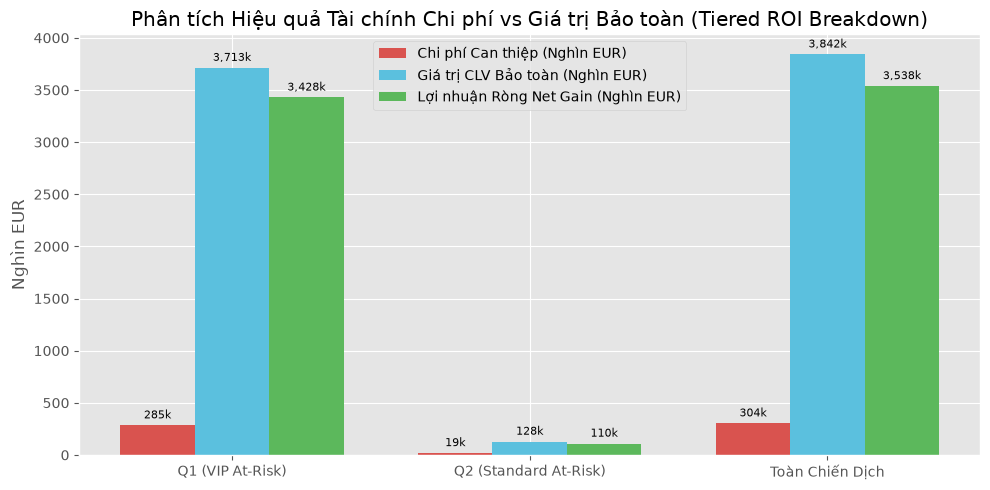

In [64]:
categories = ['Q1 (VIP At-Risk)', 'Q2 (Standard At-Risk)', 'Toàn Chiến Dịch']
costs = [
    roi_results['Q1_VIP']['intervention_cost_eur'] / 1e3,
    roi_results['Q2_Standard']['intervention_cost_eur'] / 1e3,
    roi_results['Total_Campaign']['total_intervention_cost_eur'] / 1e3
]
values = [
    roi_results['Q1_VIP']['clv_value_saved_eur'] / 1e3,
    roi_results['Q2_Standard']['clv_value_saved_eur'] / 1e3,
    roi_results['Total_Campaign']['total_clv_saved_eur'] / 1e3
]
profits = [
    roi_results['Q1_VIP']['net_profit_eur'] / 1e3,
    roi_results['Q2_Standard']['net_profit_eur'] / 1e3,
    roi_results['Total_Campaign']['total_net_profit_eur'] / 1e3
]

x = np.arange(len(categories))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width, costs, width, label='Chi phí Can thiệp (Nghìn EUR)', color='#d9534f')
rects2 = ax.bar(x, values, width, label='Giá trị CLV Bảo toàn (Nghìn EUR)', color='#5bc0de')
rects3 = ax.bar(x + width, profits, width, label='Lợi nhuận Ròng Net Gain (Nghìn EUR)', color='#5cb85c')

ax.set_ylabel('Nghìn EUR')
ax.set_title('Phân tích Hiệu quả Tài chính Chi phí vs Giá trị Bảo toàn (Tiered ROI Breakdown)')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()

# Ghi chú giá trị trên cột
for rects in [rects1, rects2, rects3]:
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f"{h:,.0f}k",
                    xy=(rect.get_x() + rect.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'fig_18_tiered_roi_breakdown.png'), dpi=300, bbox_inches='tight')
plt.show()


## 6. Tổng kết Bàn giao Sang Giai đoạn 7 (Full-Stack Web DSS Deployment)

Toàn bộ logic nghiệp vụ phân tích đề xuất đã được chứng minh và đóng gói trọn vẹn:
1. **Phân khúc 4 Góc phần tư:** Tích hợp trực tiếp lên Dashboard Điều hành và Trang Prescriptive Strategy.
2. **Next-Best-Action & Dynamic Call Scripts:** Tích hợp vào Trang Tư vấn Cá nhân hóa (Customer Retention Advisor), cho phép nhân viên chi nhánh tra cứu theo ID và nhận ngay kịch bản chăm sóc.
3. **Mô hình ROI Đa tầng:** Tích hợp vào Trang Mô phỏng ROI với các thanh trượt tương tác cho phép Ban điều hành tùy biến chi phí và tỷ lệ giữ chân theo thời gian thực.
